# Lek 정제 생산 데이터 EDA — 수율 저하 시나리오 탐색

| 항목 | 내용 |
|---|---|
| 데이터 | Lek(Sandoz) 정제 생산 공정 데이터 — `data/` 폴더 |
| 분석 대상 | 1,005개 배치 · 25개 제품 코드 · 2018-11 ~ 2021-04 |
| 목적 | **어떤 상황에서 수율이 떨어지는지(수율 저하 시나리오)** 를 데이터로 파악 |
| 실행 환경 | Python 3.12 · uv 가상환경 (`uv sync` → `uv run jupyter lab`) |

---
## 목차

| 장 | 제목 | 이 장에서 답할 질문 |
|---|---|---|
| 0 | 개요와 분석 계획 | 무엇을, 어떤 순서로 볼 것인가? |
| 1 | 환경 설정 및 데이터 로드 | 파일은 몇 개이고 크기는 어떤가? |
| 2 | 데이터 구조 이해 | 테이블은 어떻게 연결되고, 각 컬럼은 무엇을 뜻하는가? |
| 3 | 데이터 품질 점검 | 분석 전에 고쳐야 할 문제는 무엇인가? |
| 4 | 타깃(수율) 이해 | 수율은 어떻게 분포하고, '저수율'은 어떻게 정의할까? |
| 5 | 구조적 요인: 제품·배치 속성 | 제품·함량·배치 크기·시기에 따라 수율이 다른가? |
| 6 | 캠페인(연속 생산) 구조 | 캠페인의 첫 배치는 수율이 낮은가? |
| 7 | 공정 운전 변수 | 어떤 운전 패턴이 저수율과 함께 나타나는가? |
| 8 | 원자재·품질 검사 변수 | 원료 물성·로트가 수율에 영향을 주는가? |
| 9 | 시계열 심층 비교 | 저수율 배치의 생산 과정은 실제로 어떻게 다른가? |
| 10 | 수율 저하 시나리오 종합 | 결국 어떤 시나리오에서 수율이 떨어지는가? |
| 11 | 결론 및 다음 단계 | 무엇을 확인했고, 다음에 무엇을 해야 하는가? |

---
## 0. 개요와 분석 계획

### 0.1 분석 목적

정제(tablet) 생산에서 **수율(yield)** 은 이론 생산량 대비 실제로 얻은 양품의 비율입니다.
이 노트북의 목표는 **"수율이 떨어지는 배치는 어떤 조건에서 생기는가"** 를 데이터로 설명하는 것입니다.
예측 모델을 만드는 것이 아니라, 다음 단계(원인 분석·모델링)를 위한 **가설(시나리오)을 세우는 것**이 목적입니다.

### 0.2 데이터 구성

| 파일 | 단위 | 크기 | 내용 |
|---|---|---|---|
| `Laboratory.csv` | 배치 1행 | 1,005 × 55 | 원자재 물성·로트, 공정 중 정제 검사(IPC), **수율**, 출하 품질 |
| `Process.csv` | 배치 1행 | 1,005 × 35 | 시계열에서 추출한 공정 요약 변수(속도·정지·폐기량·압축력 등) |
| `Normalization.csv` | 제품 1행 | 25 × 3 | 제품 코드별 표준 배치 크기와 정규화 계수 |
| `Process.zip` | 10초 1행 | 약 470만 행 | 제품 코드별 타정기(tablet press) 원시 시계열 25개 파일 |

- 모든 테이블은 **`batch`(배치 번호)** 로 연결됩니다.
- `Process.csv` 의 일부 변수(속도 변경 횟수, 정지 시간, 폐기량)는 배치 크기에 따라 커지기 때문에
  **정규화 계수(= 배치 크기 / 100,000)로 나눈 값**입니다. 즉 "10만 정당" 값으로 해석합니다.

### 0.3 분석 계획

수율 저하의 원인을 **세 개의 층**으로 나누어 살펴봅니다.
바깥 층에서 차이가 설명되면, 안쪽 층을 볼 때 그 효과를 걸러내야 하기 때문입니다.

| 층 | 의미 | 해당 장 |
|---|---|---|
| ① 구조적 요인 | 생산 전에 이미 정해진 조건 (제품, 함량, 배치 크기, 캠페인 순번, 시기) | 5장, 6장 |
| ② 운전 요인 | 생산 중에 생기는 일 (정지, 속도 변경, 시작 단계 손실, 압축력 변동) | 7장, 9장 |
| ③ 원자재 요인 | 투입 원료의 물성과 로트 | 8장 |

**저수율 정의**: `batch_yield` 가 전체 배치의 **하위 10%** 에 속하면 저수율 배치로 봅니다(4.3절).
절대 기준이 없는 데이터이므로, 상대 기준으로 "눈에 띄게 나쁜 배치"를 골라내는 방식입니다.

**주의할 점**
- 상관관계는 인과관계가 아닙니다. 이 노트북의 결론은 모두 **"가설"** 이며, 공정 담당자의 확인이 필요합니다.
- `total_waste`(폐기량)는 수율 계산에 직접 들어가는 값이므로 **원인이 아니라 증상**으로 다룹니다.
  우리가 찾는 것은 "무엇이 폐기를 늘리는가"입니다.

---
## 1. 환경 설정 및 데이터 로드

### 1.1 라이브러리와 시각화 설정

- 한글 폰트: `koreanize-matplotlib` 가 나눔고딕을 자동으로 설정합니다.
- 색상 규칙: **정상 배치 = 파란색**, **저수율 배치 = 주황색**, 기타 = 회색 으로 노트북 전체에서 통일합니다.

In [1]:
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import koreanize_matplotlib  # noqa: F401  (import 만으로 한글 폰트 설정)
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

# ── 경로: data/ 폴더가 보일 때까지 상위 폴더로 올라가 저장소 루트를 찾음 ──
ROOT = Path.cwd()
while not (ROOT / "data" / "Laboratory.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"

# ── 색상 (노트북 전체 공통) ──────────────────────────
C_NORMAL = "#2a78d6"   # 정상 배치
C_LOW = "#eb6834"      # 저수율 배치
C_GRAY = "#9a9893"     # 보조
C_TEXT2 = "#52514e"    # 보조 텍스트
PALETTE = {"정상": C_NORMAL, "저수율": C_LOW}

plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": C_TEXT2,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.6,
    "xtick.color": C_TEXT2,
    "ytick.color": C_TEXT2,
    "legend.frameon": False,
    "axes.unicode_minus": False,
    "axes.axisbelow": True,
})

### 1.2 데이터 로드

`Process.zip` 은 압축을 풀면 약 350MB 이므로, 압축을 풀지 않고 필요한 파일만 직접 읽습니다.

In [2]:
lab = pd.read_csv(DATA_DIR / "Laboratory.csv", sep=";")
proc = pd.read_csv(DATA_DIR / "Process.csv", sep=";")
norm = pd.read_csv(DATA_DIR / "Normalization.csv", sep=";")

ZIP_PATH = DATA_DIR / "Process.zip"
with zipfile.ZipFile(ZIP_PATH) as z:
    ts_info = pd.DataFrame(
        [(int(Path(i.filename).stem), i.file_size / 1e6) for i in z.infolist() if i.filename.endswith(".csv")],
        columns=["code", "size_MB"],
    ).sort_values("code").reset_index(drop=True)

overview = pd.DataFrame({
    "테이블": ["Laboratory", "Process", "Normalization", "Process.zip (시계열)"],
    "행 수": [len(lab), len(proc), len(norm), f"{len(ts_info)}개 파일"],
    "열 수": [lab.shape[1], proc.shape[1], norm.shape[1], 16],
})
display(overview)
print(f"시계열 파일 총 크기(압축 해제 시): {ts_info.size_MB.sum():,.0f} MB")

,테이블,행 수,열 수
0,Laboratory,1005,55
1,Process,1005,35
2,Normalization,25,3
3,Process.zip (시계열),25개 파일,16


시계열 파일 총 크기(압축 해제 시): 346 MB


In [3]:
def read_ts(code: int, usecols=None) -> pd.DataFrame:
    # 제품 코드 하나의 원시 시계열(10초 간격)을 zip 에서 바로 읽는다.
    with zipfile.ZipFile(ZIP_PATH) as z, z.open(f"Process/{code}.csv") as f:
        return pd.read_csv(f, sep=";", usecols=usecols)


read_ts(1).head()

,timestamp,campaign,batch,code,tbl_speed,fom,main_comp,tbl_fill,SREL,pre_comp,produced,waste,cyl_main,cyl_pre,stiffness,ejection
0,2018-11-22 23:07:27,4,26,1,0.000,0.000,0.200,4.090,0.000,0.000,0.000,0.000,1.060,4.000,3.000,90.000
1,2018-11-22 23:07:37,4,26,1,0.000,0.000,0.200,4.090,0.000,0.000,0.000,0.000,1.060,4.000,3.000,90.000
2,2018-11-22 23:07:47,4,26,1,0.000,0.000,0.200,4.090,0.000,0.000,0.000,0.000,1.060,4.000,3.000,90.000
3,2018-11-22 23:07:57,4,26,1,0.000,0.000,0.200,4.090,0.000,0.000,0.000,0.000,1.060,4.000,3.000,90.000
4,2018-11-22 23:08:07,4,26,1,0.000,0.000,0.200,4.090,0.000,0.000,0.000,0.000,1.060,4.000,3.000,90.000


---
## 2. 데이터 구조 이해

### 2.1 테이블 간 관계

`batch` 가 모든 테이블을 잇는 키라는 가정을 확인합니다.

In [4]:
ts_batches = set()
for c in ts_info.code:
    ts_batches |= set(read_ts(c, usecols=["batch"]).batch.unique())

checks = {
    "Laboratory: batch 중복 없음": lab.batch.is_unique,
    "Process: batch 중복 없음": proc.batch.is_unique,
    "Laboratory ↔ Process: 같은 배치 집합": set(lab.batch) == set(proc.batch),
    "Laboratory ↔ Process: 같은 행 순서": (lab.batch.values == proc.batch.values).all(),
    "Laboratory ↔ Process: 제품 코드 일치": (lab.code.values == proc.code.values).all(),
    "시계열 ↔ Laboratory: 같은 배치 집합": ts_batches == set(lab.batch),
    "Normalization: 코드 1~25 모두 존재": set(norm["Product code"]) == set(lab.code),
}
pd.Series(checks, name="결과").to_frame()

,결과
Laboratory: batch 중복 없음,True
Process: batch 중복 없음,True
Laboratory ↔ Process: 같은 배치 집합,True
Laboratory ↔ Process: 같은 행 순서,True
Laboratory ↔ Process: 제품 코드 일치,True
시계열 ↔ Laboratory: 같은 배치 집합,True
Normalization: 코드 1~25 모두 존재,True


```
 Normalization (제품 코드 25행)
        │ code
        ▼
 Laboratory (배치 1,005행) ──batch── Process (배치 1,005행)
        │ batch                               ▲
        ▼                                     │ 배치별 요약(특징 추출)
 Process.zip 시계열 (10초 간격, 약 470만 행) ───┘
```

### 2.2 컬럼 사전

컬럼 이름이 약어로 되어 있어 의미를 그룹별로 정리했습니다.
의미는 원 데이터 논문(Žagar & Mihelič, *Scientific Data*, 2022)과 함께 제공된 문서를 바탕으로 했고,
확실하지 않은 항목은 **(추정)** 으로 표시했습니다.

In [5]:
col_dict = [
    # (테이블, 그룹, 컬럼, 설명)
    ("Laboratory", "식별·제품", "batch / code", "배치 번호 / 제품 코드(1~25)"),
    ("Laboratory", "식별·제품", "strength", "함량 (5MG, 10M, 20M, 40M = 5/10/20/40 mg)"),
    ("Laboratory", "식별·제품", "size", "배치 크기(정제 수)"),
    ("Laboratory", "식별·제품", "start", "생산 시작 월 (슬로베니아어 약어, 예: maj.19 = 2019년 5월)"),
    ("Laboratory", "원료의약품(API)", "api_code / api_batch", "API 공급원 코드 / API 로트 번호"),
    ("Laboratory", "원료의약품(API)", "api_water, api_content", "API 수분(%) / 함량(%)"),
    ("Laboratory", "원료의약품(API)", "api_total_impurities, api_l_impurity", "API 총 불순물 / 불순물 L"),
    ("Laboratory", "원료의약품(API)", "api_ps01 / ps05 / ps09", "API 입도 분포 D10 / D50 / D90"),
    ("Laboratory", "부형제", "smcc_batch, lactose_batch, starch_batch", "부형제(SMCC·유당·전분) 로트 번호"),
    ("Laboratory", "부형제", "lactose_water, lactose_sieve*", "유당 수분 / 체 분석 결과"),
    ("Laboratory", "부형제", "smcc_water, smcc_td, smcc_bd, smcc_ps*", "SMCC 수분 / 탭밀도 / 벌크밀도 / 입도"),
    ("Laboratory", "부형제", "starch_ph, starch_water", "전분 pH / 수분"),
    ("Laboratory", "공정 중 검사(IPC)", "tbl_* / fct_*", "코팅 전 정제(tbl) / 필름코팅 정제(fct)의 두께·무게·경도·지름·인장강도"),
    ("Laboratory", "공정 중 검사(IPC)", "*_rsd_weight", "정제 무게의 상대표준편차(%) — 무게 균일성"),
    ("Laboratory", "★ 수율", "tbl_yield", "타정 공정 수율(%)"),
    ("Laboratory", "★ 수율", "batch_yield", "배치 전체 수율(%) — 이 노트북의 기본 타깃"),
    ("Laboratory", "출하 품질", "dissolution_av / dissolution_min", "용출률 평균 / 최소(%)"),
    ("Laboratory", "출하 품질", "resodual_solvent, impurities_total, impurity_o, impurity_l", "잔류 용매 / 총 불순물 / 불순물 O, L"),
    ("Process", "속도·정지", "tbl_speed_mean", "타정 속도 평균(정지 구간 제외)"),
    ("Process", "속도·정지", "tbl_speed_change", "속도 변경 횟수 (10만 정당)"),
    ("Process", "속도·정지", "tbl_speed_0_duration", "속도 0(정지) 누적 시간 (10만 정당)"),
    ("Process", "속도·정지", "weekend", "주말 생산 여부"),
    ("Process", "폐기", "total_waste", "불량으로 배출된 정제 수 (10만 정당)"),
    ("Process", "폐기", "startup_waste", "본 생산 전 셋업(시작) 단계에서 버려진 정제 수"),
    ("Process", "충전", "fom_mean / fom_change", "충전 장치(Fill-O-Matic) 회전 속도 평균 / 변경 횟수"),
    ("Process", "충전", "tbl_fill_mean / sd", "충전 깊이 평균 / 표준편차"),
    ("Process", "압축", "main_CompForce *, pre_CompForce_mean", "주압축력 / 예비압축력 통계"),
    ("Process", "압축", "SREL_*", "압축력 상대 변동 지표 — 시작 단계 / 본 생산 (추정)"),
    ("Process", "압축", "cyl_height_mean, stiffness_*, ejection_*", "압축 실린더 높이 / 강성 / 정제 배출력"),
    ("Process", "시작 단계", "Startup_*", "시작 단계의 충전 깊이·압축력 통계"),
    ("Process", "출하 품질", "Drug release ..., Impurity ...", "Laboratory 의 출하 품질 컬럼과 같은 값 (3.2절)"),
    ("시계열", "식별", "timestamp, campaign, batch, code", "10초 간격 시각 / 캠페인 번호 / 배치 / 제품"),
    ("시계열", "운전", "tbl_speed, fom", "타정 속도 / 충전 장치 속도"),
    ("시계열", "운전", "main_comp, pre_comp, tbl_fill, SREL", "주압축력 / 예비압축력 / 충전 깊이 / 압축력 변동"),
    ("시계열", "카운터", "produced, waste", "누적 생산량(천 정) / 누적 폐기 정제 수 — 중간에 0으로 리셋되기도 함"),
    ("시계열", "기계", "cyl_main, cyl_pre, stiffness, ejection", "실린더 높이 / 강성 / 배출력"),
]
pd.DataFrame(col_dict, columns=["테이블", "그룹", "컬럼", "설명"]).style.hide(axis="index")

테이블,그룹,컬럼,설명
Laboratory,식별·제품,batch / code,배치 번호 / 제품 코드(1~25)
Laboratory,식별·제품,strength,"함량 (5MG, 10M, 20M, 40M = 5/10/20/40 mg)"
Laboratory,식별·제품,size,배치 크기(정제 수)
Laboratory,식별·제품,start,"생산 시작 월 (슬로베니아어 약어, 예: maj.19 = 2019년 5월)"
Laboratory,원료의약품(API),api_code / api_batch,API 공급원 코드 / API 로트 번호
Laboratory,원료의약품(API),"api_water, api_content",API 수분(%) / 함량(%)
Laboratory,원료의약품(API),"api_total_impurities, api_l_impurity",API 총 불순물 / 불순물 L
Laboratory,원료의약품(API),api_ps01 / ps05 / ps09,API 입도 분포 D10 / D50 / D90
Laboratory,부형제,"smcc_batch, lactose_batch, starch_batch",부형제(SMCC·유당·전분) 로트 번호
Laboratory,부형제,"lactose_water, lactose_sieve*",유당 수분 / 체 분석 결과


### 2.3 제품 구성

제품 코드 25개는 함량 4종(5·10·20·40 mg)으로 나뉘며, 배치 크기는 제품마다 다릅니다.
배치 수가 제품마다 크게 달라서, 전체 통계는 일부 대형 제품(17, 23, 13번)의 영향을 많이 받습니다.

code,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
함량,5MG,10M,20M,40M,5MG,10M,20M,40M,5MG,20M,5MG,10M,10M,5MG,40M,5MG,20M,10M,5MG,40M,5MG,10M,20M,40M,5MG
배치수,95,17,16,22,3,2,8,2,4,27,15,21,131,11,64,2,207,1,17,4,68,41,187,6,34
대표_배치크기,240000,1920000,960000,583000,2400000,2400000,1200000,1100000,240000,960000,480000,1920000,1920000,4800000,1100000,4800000,960000,1920000,240000,1100000,240000,1920000,960000,1100000,240000
배치크기_종류,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
표준_배치크기,240000,1920000,960000,583000,2400000,2400000,1200000,1100000,240000,960000,480000,1920000,1920000,480000,1100000,480000,960000,1920000,240000,1100000,240000,1920000,960000,1100000,240000


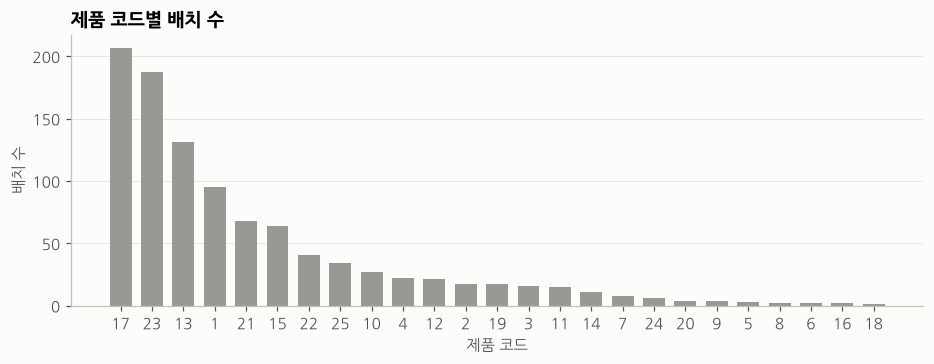

In [6]:
prod_tbl = (
    lab.groupby("code")
    .agg(함량=("strength", "first"), 배치수=("batch", "size"),
         대표_배치크기=("size", lambda s: s.mode().iat[0]), 배치크기_종류=("size", "nunique"))
    .join(norm.set_index("Product code")["Batch Size (tablets)"].rename("표준_배치크기"))
)
display(prod_tbl.T)

fig, ax = plt.subplots(figsize=(10, 3.2))
order = prod_tbl.sort_values("배치수", ascending=False)
ax.bar(order.index.astype(str), order["배치수"], color=C_GRAY, width=0.7)
ax.set_title("제품 코드별 배치 수")
ax.set_xlabel("제품 코드")
ax.set_ylabel("배치 수")
ax.grid(axis="x", visible=False)
plt.show()

In [7]:
# 실제 배치 크기와 Normalization.csv 의 표준 배치 크기가 다른 제품
prod_tbl.loc[prod_tbl["대표_배치크기"] != prod_tbl["표준_배치크기"], ["함량", "배치수", "대표_배치크기", "표준_배치크기"]]

,함량,배치수,대표_배치크기,표준_배치크기
code,,,,
14,5MG,11,4800000,480000
16,5MG,2,4800000,480000


In [8]:
pd.crosstab(lab["strength"], lab["size"], margins=True, margins_name="합계")

size,240000,480000,583000,960000,1100000,1200000,1920000,2400000,4800000,합계
strength,,,,,,,,,,
10M,0,0,0,0,0,0,211,2,0,213
20M,0,0,0,437,0,8,0,0,0,445
40M,0,0,22,0,76,0,0,0,0,98
5MG,218,15,0,0,0,0,0,3,13,249
합계,218,15,22,437,76,8,211,5,13,1005


> **해석**
>
> - 제품 코드마다 배치 크기는 **한 가지로 고정**되어 있습니다. 즉 "배치 크기"는 사실상 제품의 속성입니다.
> - **함량과 배치 크기가 강하게 묶여 있습니다.** 10 mg은 모두 1.92M, 20 mg은 대부분 960k, 5 mg은 대부분 240k입니다.
>   따라서 "함량 효과"와 "배치 크기 효과"를 구분하려면 같은 함량 안에서 비교해야 합니다(5.2절).
> - 배치의 52%가 제품 17·23·13번 세 개에 몰려 있습니다. 전체 통계는 이 제품들의 영향을 크게 받습니다.
> - ⚠️ **데이터 불일치**: 제품 14·16번은 실제 배치 크기가 4,800,000인데 `Normalization.csv` 에는 480,000으로 적혀 있습니다(10배 차이).
>   둘 중 하나는 입력 오류로 보입니다. 이 두 제품(13개 배치)의 정규화 변수(정지 시간 등)는 해석할 때 주의가 필요합니다.

---
## 3. 데이터 품질 점검

### 3.1 결측치와 공백 문자열

숫자여야 할 API 컬럼 6개가 문자열로 읽힙니다. 값이 비어 있는 자리에 **공백 문자열**이 들어 있기 때문입니다.
공백을 결측(NaN)으로 바꾸고 숫자로 변환합니다.

In [9]:
obj_cols = [c for c in lab.columns if lab[c].dtype == object or str(lab[c].dtype).startswith("str")]
obj_cols = [c for c in obj_cols if c not in ("strength", "start")]
blank_cnt = {c: int(lab[c].astype(str).str.strip().eq("").sum()) for c in obj_cols}
print("문자열로 읽힌 숫자 컬럼과 공백 개수:", blank_cnt)

for c in obj_cols:
    lab[c] = pd.to_numeric(lab[c].astype(str).str.strip().replace("", np.nan), errors="coerce")

miss = pd.concat({
    "Laboratory": lab.isna().sum(),
    "Process": proc.isna().sum(),
}).loc[lambda s: s > 0].rename("결측 수").to_frame()
miss["결측 비율"] = miss["결측 수"] / len(lab)
miss.sort_values("결측 수", ascending=False).style.format({"결측 비율": "{:.1%}"})

문자열로 읽힌 숫자 컬럼과 공백 개수: {'api_water': 26, 'api_total_impurities': 62, 'api_l_impurity': 361, 'api_ps01': 26, 'api_ps05': 26, 'api_ps09': 26}


> **해석**
>
> - `api_l_impurity` 는 37%가 비어 있습니다. 검출 한계 미만이라 기록하지 않았을 가능성이 있지만 **(추정)**, 데이터로는 확인할 수 없습니다.
>   이 변수는 결측 여부 자체가 정보일 수 있으므로 단순 대체(평균 등)는 피합니다.
> - 나머지 결측은 3% 이하로 적어서, 이 노트북에서는 결측을 그대로 둡니다(통계 계산 시 자동 제외).
> - `Process` 의 출하 품질 결측 18건은 3.2절에서 다룹니다.

### 3.2 중복 컬럼: 출하 품질 값

`Process.csv` 의 출하 품질 컬럼 6개는 `Laboratory.csv` 의 컬럼과 이름만 다르고 값은 같은지 확인합니다.

In [10]:
dup_pairs = {
    "dissolution_av": "Drug release average (%)", "dissolution_min": "Drug release min (%)",
    "resodual_solvent": "Residual solvent", "impurities_total": "Total impurities",
    "impurity_o": "Impurity O", "impurity_l": "Impurity L",
}
rows = []
for a, b in dup_pairs.items():
    both = lab[a].notna() & proc[b].notna()
    rows.append({
        "Laboratory": a, "Process": b,
        "둘 다 값 있음": int(both.sum()),
        "값 일치": int(np.isclose(lab.loc[both, a], proc.loc[both, b]).sum()),
        "Laboratory만 값 있음": int((lab[a].notna() & proc[b].isna()).sum()),
    })
pd.DataFrame(rows)

,Laboratory,Process,둘 다 값 있음,값 일치,Laboratory만 값 있음
0,dissolution_av,Drug release average (%),987,987,18
1,dissolution_min,Drug release min (%),987,987,18
2,resodual_solvent,Residual solvent,987,987,18
3,impurities_total,Total impurities,987,987,18
4,impurity_o,Impurity O,987,987,18
5,impurity_l,Impurity L,987,987,18


> **해석**
>
> - 두 테이블의 값은 **둘 다 값이 있는 987개 배치에서 모두 일치**합니다. 같은 데이터가 두 번 들어 있는 것입니다.
> - `Laboratory` 는 `Process` 에서 비어 있는 18개 배치의 값까지 갖고 있으므로, **출하 품질은 `Laboratory` 컬럼만 사용**하고 `Process` 쪽 중복 컬럼은 버립니다.

### 3.3 날짜 문제 ① — 생산 시작 월(`start`)

`start` 는 `nov.18`, `maj.19`, `avg.19` 처럼 **슬로베니아어 월 약어**로 되어 있어 직접 변환합니다.

In [11]:
SLO_MONTH = {"jan": 1, "feb": 2, "mar": 3, "apr": 4, "maj": 5, "jun": 6,
             "jul": 7, "avg": 8, "sep": 9, "okt": 10, "nov": 11, "dec": 12}
mon, yr = lab["start"].str.split(".", expand=True).T.values
lab["start_month"] = pd.to_datetime({"year": 2000 + yr.astype(int), "month": pd.Series(mon).map(SLO_MONTH), "day": 1})

print("변환 실패:", lab["start_month"].isna().sum())
print("기간:", lab["start_month"].min().strftime("%Y-%m"), "~", lab["start_month"].max().strftime("%Y-%m"))
months = pd.date_range(lab["start_month"].min(), lab["start_month"].max(), freq="MS")
print("배치가 없는 달:", [m.strftime("%Y-%m") for m in months if m not in set(lab["start_month"])])

변환 실패: 0
기간: 2018-11 ~ 2021-04
배치가 없는 달: ['2020-07']


### 3.4 날짜 문제 ② — 시계열 타임스탬프

시계열 파일의 타임스탬프에는 두 가지 문제가 있습니다.

1. **형식 혼재**: 21개 파일은 `2018-11-22 23:07:27`, 4개 파일(13, 15, 17, 23번)은 `07052019 20:14`(일월연도, 초 없음) 형식입니다.
2. **일·월 뒤바뀜 의심**: 시계열에서 계산한 배치 시작일이 `start` 월과 몇 달씩 어긋나는 배치가 있습니다.

아래에서 각 배치의 시계열 요약을 만들면서 이 문제를 확인합니다.

In [12]:
def parse_ts(s: pd.Series) -> pd.Series:
    # 두 가지 형식을 순서대로 시도한다.
    t = pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    miss = t.isna()
    t[miss] = pd.to_datetime(s[miss], format="%d%m%Y %H:%M", errors="coerce")
    return t


fmt_rows, ts_rows = [], []
for c in ts_info.code:
    df = read_ts(c, usecols=["timestamp", "campaign", "batch", "tbl_speed", "produced"])
    iso = df.timestamp.str.match(r"^\d{4}-\d{2}-\d{2} ").mean()
    fmt_rows.append({"code": c, "형식": "YYYY-MM-DD hh:mm:ss" if iso == 1 else "DDMMYYYY hh:mm", "행 수": len(df)})
    df["ts"] = parse_ts(df.timestamp)
    ts_rows.append(
        df.groupby("batch").agg(
            campaign=("campaign", "first"),
            ts_start=("ts", "min"),
            n_samples=("ts", "size"),
            stop_ratio=("tbl_speed", lambda x: (x == 0).mean()),
            produced_k=("produced", "max"),
        )
    )

fmt_df = pd.DataFrame(fmt_rows)
ts_sum = pd.concat(ts_rows)
print("타임스탬프 변환 실패:", ts_sum.ts_start.isna().sum())
fmt_df.groupby("형식").agg(파일수=("code", "size"), 제품코드=("code", list), 총행수=("행 수", "sum"))

타임스탬프 변환 실패: 0


,파일수,제품코드,총행수
형식,,,
DDMMYYYY hh:mm,4,"[13, 15, 17, 23]",3003033
YYYY-MM-DD hh:mm:ss,21,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 16...",1717175


In [13]:
def month_gap(t: pd.Series, ref: pd.Series) -> pd.Series:
    return (t.dt.year - ref.dt.year) * 12 + (t.dt.month - ref.dt.month)


def swap_day_month(t: pd.Series) -> pd.Series:
    # 일이 12 이하인 경우에만 일과 월을 바꾼다 (그 외는 바꿀 수 없음).
    ok = t.dt.day <= 12
    out = t.copy()
    out[ok] = pd.to_datetime({"year": t[ok].dt.year, "month": t[ok].dt.day, "day": t[ok].dt.month,
                              "hour": t[ok].dt.hour, "minute": t[ok].dt.minute})
    return out


chk = ts_sum.join(lab.set_index("batch")["start_month"])
chk["gap_raw"] = month_gap(chk.ts_start, chk.start_month)
chk["gap_swap"] = month_gap(swap_day_month(chk.ts_start), chk.start_month)

summary = pd.DataFrame({
    "원본 타임스탬프": chk.gap_raw.abs().le(1).value_counts(),
    "일·월 교환 후": chk[["gap_raw", "gap_swap"]].abs().min(axis=1).le(1).value_counts(),
}).rename(index={True: "start 월과 ±1개월 이내", False: "2개월 이상 어긋남"})
display(summary)

print("어긋난 배치 예시 (시계열 시작 시각 vs start 월):")
chk.loc[chk.gap_raw.abs() > 1, ["campaign", "ts_start", "start_month", "gap_raw", "gap_swap"]].head(6)

,원본 타임스탬프,일·월 교환 후
2개월 이상 어긋남,138,NaN
start 월과 ±1개월 이내,867,"1,005.000"


어긋난 배치 예시 (시계열 시작 시각 vs start 월):


,campaign,ts_start,start_month,gap_raw,gap_swap
batch,,,,,
294,66,2019-01-07 02:25:49,2019-06-01,-5,1
295,66,2019-01-07 05:39:12,2019-06-01,-5,1
296,66,2019-01-07 08:40:04,2019-06-01,-5,1
297,66,2019-01-07 11:44:00,2019-06-01,-5,1
298,66,2019-01-07 14:46:28,2019-06-01,-5,1
306,67,2019-01-07 17:57:14,2019-06-01,-5,1


> **해석**
>
> - **형식 혼재**: 13·15·17·23번 파일(약 300만 행, 전체의 64%)은 `일월연도 시:분` 형식이고 초 단위가 없습니다.
> - **일·월 뒤바뀜 확인**: 원본 타임스탬프로는 138개 배치(13.7%)의 시작일이 `start` 월과 2개월 이상 어긋납니다.
>   그런데 **일과 월을 바꾸면 1,005개 배치 모두가 ±1개월 안으로 들어옵니다.**
>   예) 배치 294는 `2019-01-07` 로 기록되어 있지만 실제로는 `2019-07-01` (start = 2019년 6~7월).
>   → 원본 시스템에서 일부 날짜가 **일/월이 뒤바뀐 채 저장**되었습니다. 두 형식 모두에서 나타납니다.
> - **이 노트북의 대응**
>   - 달력 기준 분석(월별 추세)은 `start` 월을 사용합니다.
>   - 배치 내부 시계열은 절대 시각 대신 **샘플 순서 × 10초(경과 시간)** 를 사용합니다.
>   - 배치 순서는 **배치 번호**로 정합니다(배치 번호와 생산 월의 순위 상관 0.999, 4.4절).

### 3.5 극단값 확인

공정 요약 변수 중 **최댓값이 99번째 백분위수보다 훨씬 큰** 변수를 찾습니다.
극단값은 지우지 않고, 이후 분석에서 순위 기반 통계(스피어만 상관, 중앙값, 사분위)를 써서 영향을 줄입니다.

In [14]:
pnum = proc.drop(columns=["batch", "code"]).select_dtypes("number")
tail = pd.DataFrame({
    "중앙값": pnum.median(),
    "99%": pnum.quantile(0.99),
    "최댓값": pnum.max(),
})
tail["최댓값 / 99%"] = tail["최댓값"] / tail["99%"].replace(0, np.nan)
tail.sort_values("최댓값 / 99%", ascending=False).head(10)

,중앙값,99%,최댓값,최댓값 / 99%
tbl_speed_change,2.500,16.650,145.417,8.734
fom_change,10.000,37.000,308.000,8.324
SREL_production_max,7.300,14.500,83.000,5.724
ejection_max,220.000,849.480,"4,747.000",5.588
ejection_mean,184.432,477.806,"2,253.668",4.717
tbl_speed_0_duration,47.273,258.792,"1,118.125",4.321
SREL_startup_mean,6.061,19.715,55.569,2.819
total_waste,759.348,"3,870.583","10,542.917",2.724
tbl_fill_sd,0.068,0.196,0.489,2.496
main_CompForce_sd,0.089,0.759,1.770,2.332


> **해석**
>
> - 속도 변경 횟수, 충전 장치 속도 변경 횟수, SREL 최댓값, 배출력은 최댓값이 99번째 백분위수의 4~9배인 **긴 꼬리**를 가집니다.
> - 이런 극단값은 실제 공정 이상일 수도, 센서 오류일 수도 있습니다. 판단 근거가 없으므로 지우지 않고,
>   이후 분석에서는 순위 기반 통계(스피어만 상관, 중앙값, 사분위, 클리프 δ)를 써서 영향을 줄입니다.

---
## 4. 타깃(수율) 이해

### 4.1 두 가지 수율: `tbl_yield` vs `batch_yield`

- `tbl_yield`: 타정 공정까지의 수율
- `batch_yield`: 코팅 등 이후 공정까지 포함한 **배치 전체 수율**

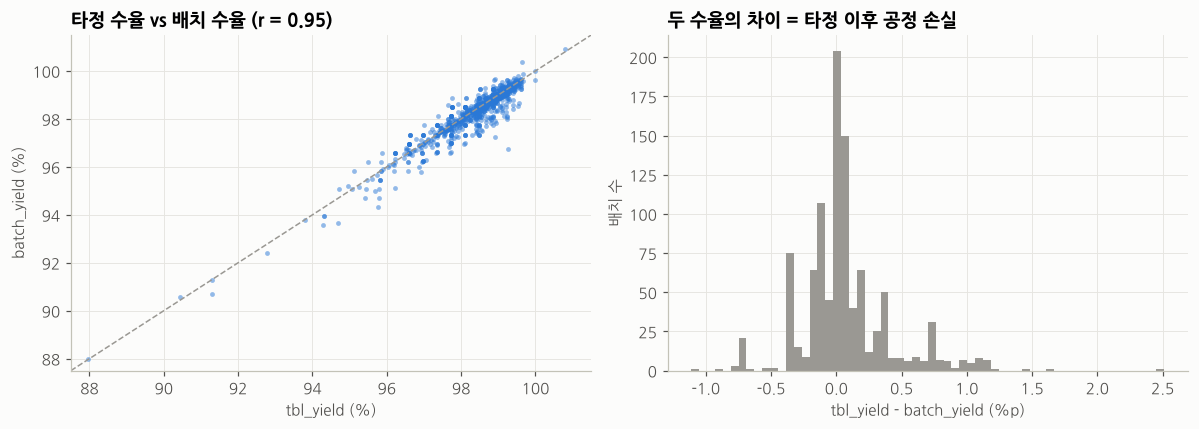

두 수율이 같은 배치: 19.7%   |   차이 중앙값: 0.000%p   |   100% 초과 배치: 2개


In [15]:
r = lab[["tbl_yield", "batch_yield"]].corr().iat[0, 1]
diff = lab.tbl_yield - lab.batch_yield

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ax = axes[0]
ax.scatter(lab.tbl_yield, lab.batch_yield, s=10, alpha=0.5, color=C_NORMAL, linewidths=0)
lims = [87.5, 101.5]
ax.plot(lims, lims, color=C_GRAY, lw=1, ls="--")
ax.set(xlim=lims, ylim=lims, xlabel="tbl_yield (%)", ylabel="batch_yield (%)",
       title=f"타정 수율 vs 배치 수율 (r = {r:.2f})")

ax = axes[1]
ax.hist(diff, bins=60, color=C_GRAY)
ax.set(xlabel="tbl_yield - batch_yield (%p)", ylabel="배치 수",
       title="두 수율의 차이 = 타정 이후 공정 손실")
plt.tight_layout()
plt.show()

print(f"두 수율이 같은 배치: {(diff == 0).mean():.1%}   |   차이 중앙값: {diff.median():.3f}%p   |   100% 초과 배치: {(lab.batch_yield > 100).sum()}개")

> **해석**
>
> - 두 수율의 상관은 0.95로 매우 높고, 차이의 중앙값은 0입니다. 대부분의 손실은 **타정 공정에서** 발생합니다.
> - 따라서 타정기 시계열(`Process.zip`)로 수율 저하를 설명하려는 접근이 타당합니다.
> - `batch_yield` 가 100%를 넘는 배치가 2개 있습니다. 계산·계량 오차로 보이며, 영향이 작아 그대로 둡니다.
> - 이후 분석의 타깃은 **`batch_yield`** 로 통일합니다.

### 4.2 수율 분포

,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,max
tbl_yield,"1,005.000",98.323,1.078,87.973,94.726,96.551,96.985,97.822,98.554,99.053,99.290,100.805
batch_yield,"1,005.000",98.256,1.129,87.973,94.333,96.319,96.970,97.727,98.485,99.006,99.290,100.909


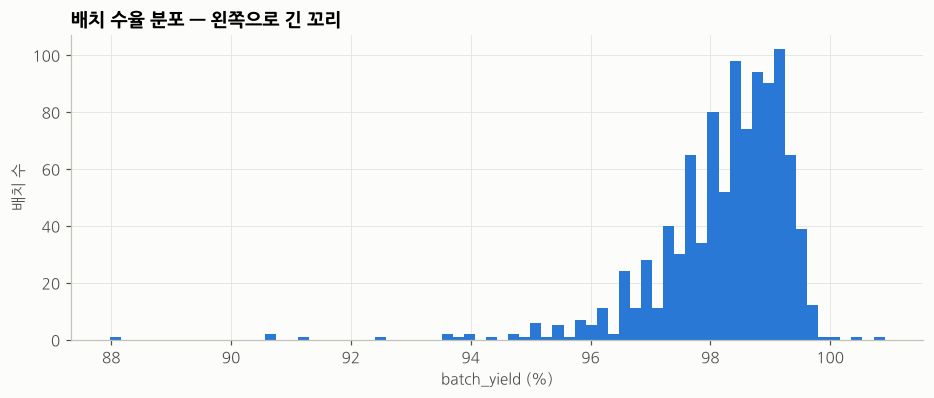

In [16]:
desc = lab[["tbl_yield", "batch_yield"]].describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9]).T
display(desc)

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.hist(lab.batch_yield, bins=70, color=C_NORMAL)
ax.set(xlabel="batch_yield (%)", ylabel="배치 수", title="배치 수율 분포 — 왼쪽으로 긴 꼬리")
plt.show()

> **해석**
>
> - 중앙값 98.5%, 중간 50% 범위 97.7~99.0%로 대부분의 배치는 좁은 범위에 모여 있습니다.
> - 분포는 **왼쪽으로 긴 꼬리**를 가집니다. 최저 88.0%, 하위 1%는 94.3% 미만입니다.
>   → 수율 저하는 "전반적으로 조금씩 낮아지는 현상"이 아니라 **일부 배치에서 크게 떨어지는 사건**에 가깝습니다.

### 4.3 저수율 배치 정의

`batch_yield` 의 **하위 10%** 를 저수율 배치로 정의합니다. 이후 모든 장에서 이 정의(`is_low`)를 사용합니다.

- 장점: 단위나 제품과 상관없이 "눈에 띄게 나쁜 배치"를 일정 비율로 골라낼 수 있습니다.
- 한계: 제품마다 정상 수율 수준이 다르므로, 수율이 원래 낮은 제품이 저수율 그룹에 많이 들어갑니다.
  그래서 7·8장에서는 **제품 코드 중앙값 대비 편차(`yield_dev`)** 도 함께 봅니다.

저수율 기준: batch_yield < 96.97%  →  저수율 배치 92개 (9.2%)


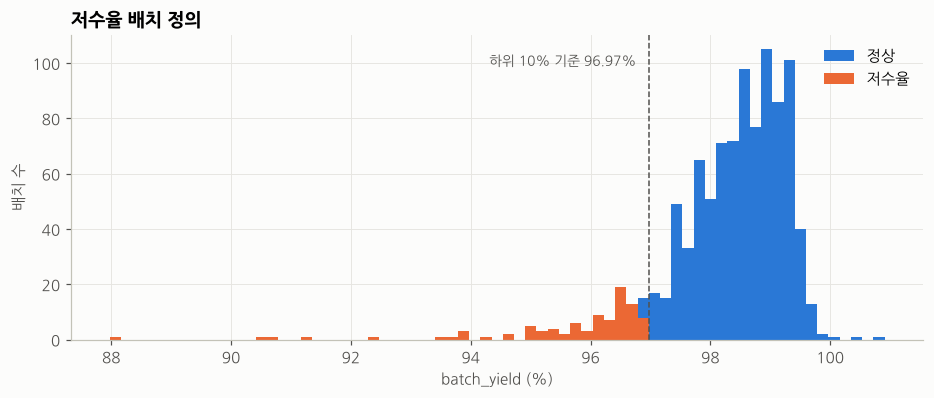

In [17]:
LOW_Q = 0.10
LOW_THR = lab.batch_yield.quantile(LOW_Q)

lab["is_low"] = lab.batch_yield < LOW_THR
lab["group"] = np.where(lab.is_low, "저수율", "정상")
# 제품 효과를 제거한 수율: 같은 제품 코드의 중앙값 대비 편차(%p)
lab["yield_dev"] = lab.batch_yield - lab.groupby("code").batch_yield.transform("median")

print(f"저수율 기준: batch_yield < {LOW_THR:.2f}%  →  저수율 배치 {lab.is_low.sum()}개 ({lab.is_low.mean():.1%})")

fig, ax = plt.subplots(figsize=(10, 3.6))
bins = np.linspace(lab.batch_yield.min(), lab.batch_yield.max(), 70)
for g in ["정상", "저수율"]:
    ax.hist(lab.loc[lab.group == g, "batch_yield"], bins=bins, color=PALETTE[g], label=g)
ax.axvline(LOW_THR, color=C_TEXT2, lw=1, ls="--")
ax.annotate(f"하위 10% 기준 {LOW_THR:.2f}%", (LOW_THR, ax.get_ylim()[1] * 0.9), xytext=(-8, 0),
            textcoords="offset points", ha="right", color=C_TEXT2, fontsize=9)
ax.set(xlabel="batch_yield (%)", ylabel="배치 수", title="저수율 배치 정의")
ax.legend()
plt.show()

### 4.4 분석용 배치 테이블 만들기

이후 분석을 위해 세 소스를 배치 단위로 합칩니다.

- `lab` 전체 + `proc` 의 공정 요약 변수(중복 품질 컬럼 제외) + 시계열 요약(`ts_sum`)
- 시계열에서 추가로 만든 변수
  - `campaign`: 캠페인 번호 (같은 제품을 연속 생산하는 묶음)
  - `pos_in_campaign`: 캠페인 내 몇 번째 배치인가 (배치 번호 순서)
  - `run_hours`: 시계열 기록 길이(시간) = 샘플 수 × 10초

In [18]:
proc_feats = [c for c in proc.columns if c not in ("batch", "code") and c not in dup_pairs.values()]
df = (
    lab.set_index("batch")
    .join(proc.set_index("batch")[proc_feats])
    .join(ts_sum[["campaign", "n_samples", "stop_ratio"]])
)
df["is_weekend"] = df.weekend.eq("yes")
df["run_hours"] = df.n_samples * 10 / 3600
df = df.sort_index()
df["pos_in_campaign"] = df.groupby("campaign").cumcount() + 1
df["campaign_len"] = df.groupby("campaign").campaign.transform("size")
df["first_in_campaign"] = df.pos_in_campaign.eq(1)

print("배치 테이블:", df.shape, "| 캠페인 수:", df.campaign.nunique())
print("한 캠페인 = 한 제품 코드인가?", df.groupby("campaign").code.nunique().eq(1).all())
print("배치 번호가 시간 순서인가? (배치 번호 vs 시작 월 스피어만 상관):",
      round(stats.spearmanr(df.index, df.start_month.rank())[0], 3))

배치 테이블: (1005, 93) | 캠페인 수: 187
한 캠페인 = 한 제품 코드인가? True
배치 번호가 시간 순서인가? (배치 번호 vs 시작 월 스피어만 상관): 0.999


---
## 5. 구조적 요인: 제품·배치 속성별 수율

생산 전에 이미 정해지는 조건(제품, 함량, 배치 크기, 시기)에 따라 수율이 달라지는지 봅니다.
각 그룹에 대해 **수율 중앙값**과 **저수율 비율**(그 그룹 배치 중 저수율 배치 비율)을 함께 봅니다.

In [19]:
OVERALL_LOW = df.is_low.mean()


def seg_table(by, data=None, min_n=1):
    # 그룹별 배치 수 / 수율 중앙값 / 저수율 비율
    data = df if data is None else data
    t = data.groupby(by, observed=True).agg(
        배치수=("batch_yield", "size"),
        수율_중앙값=("batch_yield", "median"),
        저수율_비율=("is_low", "mean"),
    )
    return t[t.배치수 >= min_n]


def plot_low_rate(t, title, xlabel, ax=None, rotate=0):
    # 그룹별 저수율 비율 막대 + 전체 평균선. 막대 위에 배치 수(n) 표시.
    ax = ax or plt.subplots(figsize=(8, 3.6))[1]
    x = t.index.astype(str)
    colors = [C_LOW if v > OVERALL_LOW * 1.5 else C_GRAY for v in t.저수율_비율]
    ax.bar(x, t.저수율_비율, color=colors, width=0.7)
    ax.axhline(OVERALL_LOW, color=C_TEXT2, lw=1, ls="--")
    ax.text(1.01, OVERALL_LOW, f"전체\n{OVERALL_LOW:.0%}", transform=ax.get_yaxis_transform(), va="center", ha="left",
            fontsize=8, color=C_TEXT2)
    for xi, (v, n) in enumerate(zip(t.저수율_비율, t.배치수)):
        ax.text(xi, v, f"n={n}", ha="center", va="bottom", fontsize=8, color=C_TEXT2)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set(title=title, xlabel=xlabel, ylabel="저수율 비율")
    ax.grid(axis="x", visible=False)
    ax.tick_params(axis="x", rotation=rotate)
    return ax

### 5.1 함량(strength)과 제품 코드별 수율

막대 색: 저수율 비율이 전체 평균의 1.5배를 넘으면 **주황색**입니다.

,배치수,수율_중앙값,저수율_비율
strength,,,
5MG,249,97.727,0.221
10M,213,98.864,0.019
20M,445,98.627,0.047
40M,98,98.326,0.122


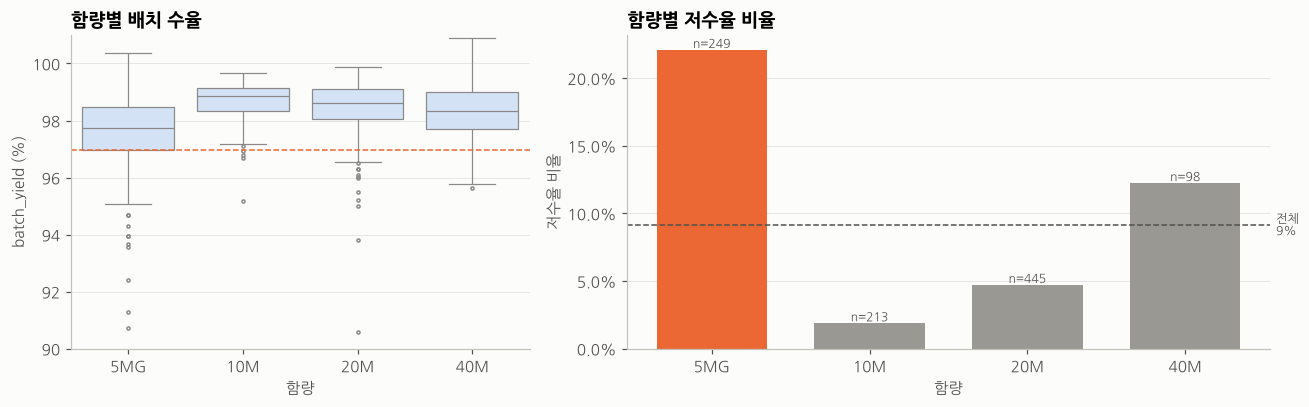

In [20]:
STRENGTH_ORDER = ["5MG", "10M", "20M", "40M"]
df["strength"] = pd.Categorical(df.strength, STRENGTH_ORDER, ordered=True)
t_str = seg_table("strength")
display(t_str)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})
sns.boxplot(data=df, x="strength", y="batch_yield", ax=axes[0], color="#cde2fb", fliersize=2,
            linewidth=0.8, order=STRENGTH_ORDER)
axes[0].axhline(LOW_THR, color=C_LOW, lw=1, ls="--")
axes[0].set(title="함량별 배치 수율", xlabel="함량", ylabel="batch_yield (%)", ylim=(90, 101))
plot_low_rate(t_str, "함량별 저수율 비율", "함량", ax=axes[1])
plt.tight_layout()
plt.show()

,배치수,수율_중앙값,저수율_비율,함량,대표_배치크기
code,,,,,
11,15,96.59,53.3%,5MG,"480,000"
21,68,97.53,29.4%,5MG,"240,000"
4,22,97.89,27.3%,40M,"583,000"
25,34,98.11,20.6%,5MG,"240,000"
1,95,97.73,13.7%,5MG,"240,000"
19,17,98.11,11.8%,5MG,"240,000"
15,64,98.62,9.4%,40M,"1,100,000"
14,11,98.37,9.1%,5MG,"4,800,000"
2,17,98.86,5.9%,10M,"1,920,000"


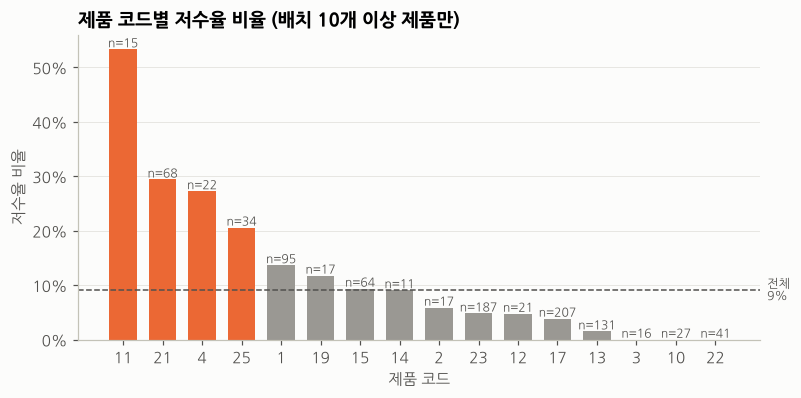

In [21]:
t_code = seg_table("code").join(prod_tbl[["함량", "대표_배치크기"]])
t_code_big = t_code[t_code.배치수 >= 10].sort_values("저수율_비율", ascending=False)
display(t_code_big.style.format({"수율_중앙값": "{:.2f}", "저수율_비율": "{:.1%}", "대표_배치크기": "{:,}"}))

plot_low_rate(t_code_big, "제품 코드별 저수율 비율 (배치 10개 이상 제품만)", "제품 코드")
plt.show()

> **해석**
>
> - **5 mg 제품의 저수율 비율은 22%로 전체(9%)의 약 2.4배**입니다. 40 mg도 12%로 평균보다 높습니다.
> - 반대로 10 mg(2%)과 20 mg(5%)은 안정적입니다.
> - 제품별로 보면 11번(53%), 21번(29%), 4번(27%), 25번(21%) 순으로 저수율 비율이 높습니다.
>   이 제품들의 공통점은 **배치 크기가 작다**(240k~583k)는 것입니다 → 5.2절에서 확인합니다.

### 5.2 배치 크기별 수율

배치 크기가 작으면 셋업 단계에서 버려지는 고정 손실의 비중이 커져 수율이 낮아질 수 있습니다.

,배치수,수율_중앙값,저수율_비율
size,,,
240000,218,97.73,20.6%
480000,15,96.59,53.3%
583000,22,97.89,27.3%
960000,437,98.63,3.9%
1100000,76,98.53,7.9%
1200000,8,97.65,50.0%
1920000,211,98.86,1.9%
2400000,5,97.77,20.0%
4800000,13,98.37,7.7%


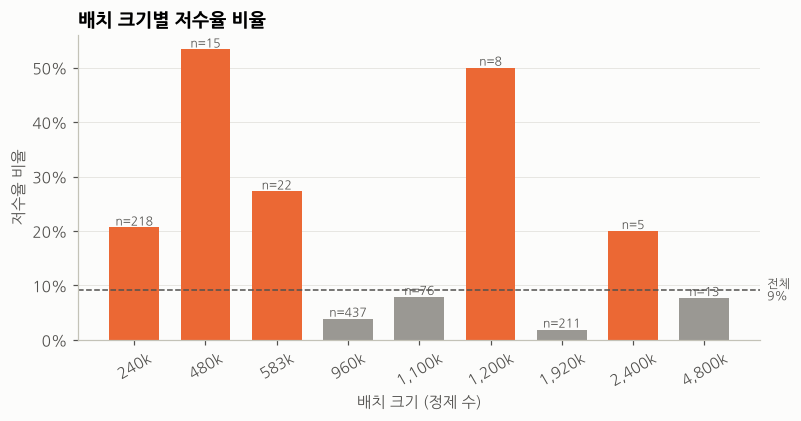

In [22]:
t_size = seg_table("size")
display(t_size.style.format({"수율_중앙값": "{:.2f}", "저수율_비율": "{:.1%}"}))

ax = plot_low_rate(t_size, "배치 크기별 저수율 비율", "배치 크기 (정제 수)", rotate=30)
ax.set_xticks(range(len(t_size)), [f"{v/1e3:,.0f}k" for v in t_size.index])
plt.show()

**함량과 배치 크기는 섞여 있습니다.** 5 mg 제품은 대부분 작은 배치(240k)로 생산됩니다.
둘 중 무엇이 진짜 요인인지 보려면 **같은 함량 안에서** 배치 크기를 비교해야 합니다.

In [23]:
df["size_class"] = pd.cut(df["size"], [0, 600_000, 1_300_000, np.inf], labels=["소형 ≤600k", "중형 ~1.2M", "대형 ≥1.9M"])
cross = df.pivot_table(index="strength", columns="size_class", values="is_low", aggfunc=["mean", "size"], observed=False)
cross_view = cross["mean"].map(lambda v: f"{v:.0%}" if pd.notna(v) else "-") + cross["size"].map(lambda n: f"  (n={n})")
cross_view

size_class,소형 ≤600k,중형 ~1.2M,대형 ≥1.9M
strength,,,
5MG,23% (n=233),- (n=0),12% (n=16)
10M,- (n=0),- (n=0),2% (n=213)
20M,- (n=0),5% (n=445),- (n=0)
40M,27% (n=22),8% (n=76),- (n=0)


> **해석**
>
> - 배치 크기 ≤ 583k 인 소형 배치의 저수율 비율은 21~53%로, 960k 이상(2~8%)보다 훨씬 높습니다.
>   (1.2M 제품 7번의 50%는 배치 8개에 불과해 해석하지 않습니다.)
> - **같은 함량 안에서도 배치 크기 효과가 남습니다.**
>   - 5 mg: 소형 23% vs 대형 12%
>   - 40 mg: 소형(583k) 27% vs 중형(1.1M) 8%
> - 해석(가설): 셋업·재시작 때 버려지는 정제 수는 배치 크기와 상관없이 어느 정도 고정되어 있으므로,
>   **작은 배치일수록 같은 손실이 수율에서 차지하는 비중이 커집니다.**

### 5.3 시기별 추세

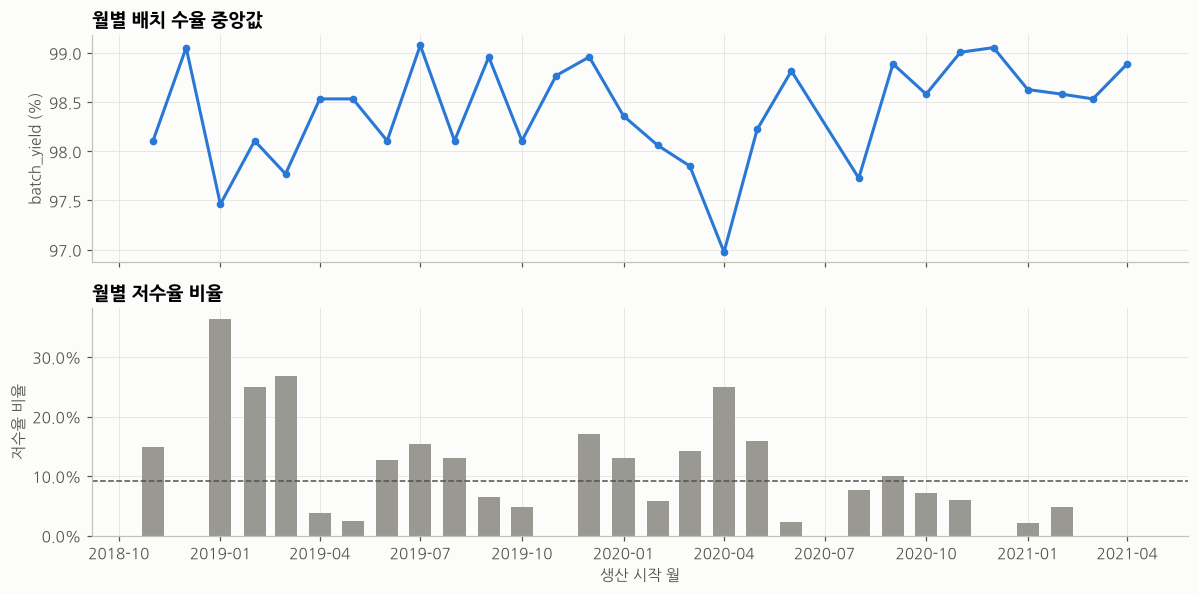

half,2018-H2,2019-H1,2019-H2,2020-H1,2020-H2,2021-H1
배치수,76.000,244.000,216.000,177.000,126.000,166.000
수율_중앙값,98.106,98.251,98.655,98.267,98.793,98.627
저수율_비율,0.132,0.135,0.088,0.102,0.071,0.018


In [24]:
t_month = seg_table("start_month")
fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(t_month.index, t_month.수율_중앙값, color=C_NORMAL, lw=2, marker="o", ms=4)
axes[0].set(title="월별 배치 수율 중앙값", ylabel="batch_yield (%)")
axes[1].bar(t_month.index, t_month.저수율_비율, width=20, color=C_GRAY)
axes[1].axhline(OVERALL_LOW, color=C_TEXT2, lw=1, ls="--")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[1].set(title="월별 저수율 비율", ylabel="저수율 비율", xlabel="생산 시작 월")
plt.tight_layout()
plt.show()

df["half"] = df.start_month.dt.year.astype(str) + "-H" + ((df.start_month.dt.month > 6) + 1).astype(str)
seg_table("half").T

> **해석**
>
> - 장기적으로 수율이 계속 나빠지는 추세는 없습니다. 오히려 후반으로 갈수록 저수율 비율이 줄어듭니다
>   (2018 하반기~2019 상반기 13% → 2021 상반기 2%).
> - 2019년 1~3월과 2020년 4월에 저수율이 몰려 있습니다. 이 시기의 제품 구성(소형 제품 비중)이나
>   설비·인력 변화가 원인일 수 있으며, **생산 기록과 대조가 필요한 시기**입니다.

### 5.4 주말 생산

In [25]:
t_wk = seg_table("is_weekend").rename(index={False: "평일", True: "주말"})
display(t_wk.style.format({"수율_중앙값": "{:.2f}", "저수율_비율": "{:.1%}"}))

# 함량을 고정해도 주말 효과가 남는지 확인
df.pivot_table(index="strength", columns="is_weekend", values="is_low", aggfunc=["mean", "size"], observed=True) \
  .rename(columns={False: "평일", True: "주말"}).style.format("{:.2f}")

,배치수,수율_중앙값,저수율_비율
is_weekend,,,
평일,950,98.48,8.6%
주말,55,97.73,18.2%


> **해석**
>
> - 주말에 생산된 배치(55개)의 저수율 비율은 18%로 평일(9%)의 약 2배입니다.
> - 함량별로 나누면 20 mg(33% vs 4%), 40 mg(18% vs 11%), 10 mg(5% vs 2%)에서 주말이 더 나쁘고, 5 mg에서는 반대입니다.
> - 다만 주말 배치 수가 함량별로 6~20개뿐이라 **우연일 가능성을 배제할 수 없습니다.**
>   인력 배치(주말 근무자 수·숙련도)와 관련된 **약한 가설**로만 남겨 둡니다.

---
## 6. 캠페인(연속 생산) 구조와 수율

**캠페인**은 같은 제품을 여러 배치 연속으로 생산하는 묶음입니다.
캠페인의 첫 배치는 제품 교체 후 기계 셋업이 필요하므로 시작 단계 손실(`startup_waste`)이 클 것으로 예상됩니다.

### 6.1 캠페인 길이 분포

캠페인 187개 | 캠페인당 배치 수 중앙값 4개 (최소 1, 최대 17)


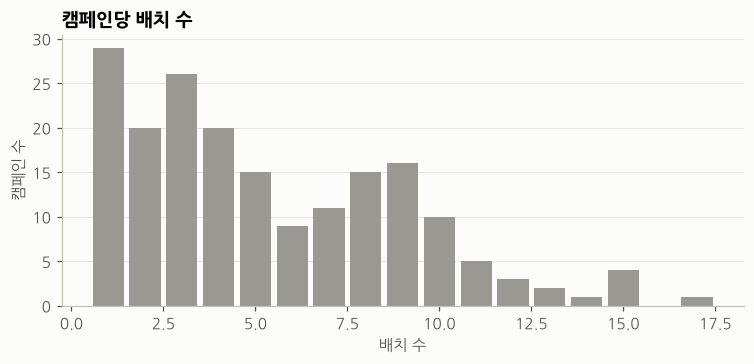

In [26]:
camp = df.groupby("campaign").agg(code=("code", "first"), 배치수=("code", "size"))
print(f"캠페인 {len(camp)}개 | 캠페인당 배치 수 중앙값 {camp.배치수.median():.0f}개 (최소 {camp.배치수.min()}, 최대 {camp.배치수.max()})")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(camp.배치수, bins=range(1, camp.배치수.max() + 2), color=C_GRAY, align="left", rwidth=0.85)
ax.set(title="캠페인당 배치 수", xlabel="배치 수", ylabel="캠페인 수")
ax.grid(axis="x", visible=False)
plt.show()

### 6.2 캠페인 내 순번별 수율

,배치수,수율_중앙값,저수율_비율,startup_waste_중앙값
pos_bin,,,,
1번째,187,97.96,20.3%,"7,272"
2번째,158,98.48,9.5%,"5,400"
3번째,138,98.65,7.2%,"5,090"
4번째 이후,522,98.63,5.6%,"3,850"


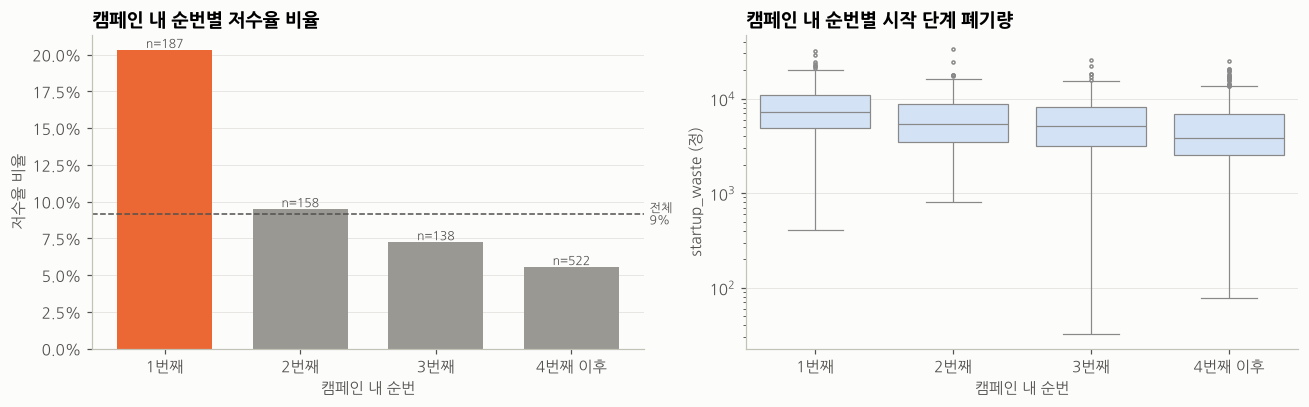

In [27]:
df["pos_bin"] = pd.cut(df.pos_in_campaign, [0, 1, 2, 3, np.inf], labels=["1번째", "2번째", "3번째", "4번째 이후"])
t_pos = seg_table("pos_bin").join(df.groupby("pos_bin", observed=True).startup_waste.median().rename("startup_waste_중앙값"))
display(t_pos.style.format({"수율_중앙값": "{:.2f}", "저수율_비율": "{:.1%}", "startup_waste_중앙값": "{:,.0f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_low_rate(t_pos, "캠페인 내 순번별 저수율 비율", "캠페인 내 순번", ax=axes[0])
sns.boxplot(data=df, x="pos_bin", y="startup_waste", ax=axes[1], color="#cde2fb", fliersize=2, linewidth=0.8)
axes[1].set(title="캠페인 내 순번별 시작 단계 폐기량", xlabel="캠페인 내 순번", ylabel="startup_waste (정)")
axes[1].set_yscale("log")
plt.tight_layout()
plt.show()

In [28]:
# 함량별로 나누어도 '첫 배치 효과'가 남는지 확인 (교란 확인)
pv = df.pivot_table(index="strength", columns="first_in_campaign", values="is_low", aggfunc="mean", observed=True)
pv.columns = ["2번째 이후", "첫 배치"]
pv["차이(%p)"] = (pv["첫 배치"] - pv["2번째 이후"]) * 100
pv.style.format({"2번째 이후": "{:.1%}", "첫 배치": "{:.1%}", "차이(%p)": "{:+.1f}"})

,2번째 이후,첫 배치,차이(%p)
strength,,,
5MG,15.4%,56.1%,+40.7
10M,1.2%,4.9%,+3.7
20M,3.7%,9.9%,+6.1
40M,9.4%,17.6%,+8.3


> **해석**
>
> - **캠페인의 첫 배치는 저수율 비율이 20%로**, 2번째(9.5%), 3번째(7%), 4번째 이후(6%)보다 크게 높습니다.
> - 시작 단계 폐기량 중앙값도 첫 배치가 7,272정으로 4번째 이후(3,850정)의 약 2배입니다.
>   → 제품 교체 후 **기계 셋업 손실이 첫 배치에 집중**됩니다.
> - **모든 함량에서 첫 배치가 더 나쁩니다.** 특히 5 mg은 첫 배치 56% vs 이후 15%로 차이가 매우 큽니다.
>   소형 배치(5.2절)와 첫 배치 효과가 겹치는 지점입니다.

---
## 7. 공정 운전 변수와 수율

`Process.csv` 의 공정 요약 변수와 시계열에서 만든 변수가 수율과 어떻게 관련되는지 봅니다.
제품 차이의 영향을 걸러내기 위해 두 가지 타깃을 함께 봅니다.

- `batch_yield`: 수율 자체
- `yield_dev`: 같은 제품 코드의 중앙값 대비 편차 → **같은 제품 안에서** 수율이 낮은 이유를 보여줌

### 7.1 수율과의 상관 순위 (스피어만)

극단값의 영향을 줄이기 위해 순위 기반 스피어만 상관계수를 씁니다.

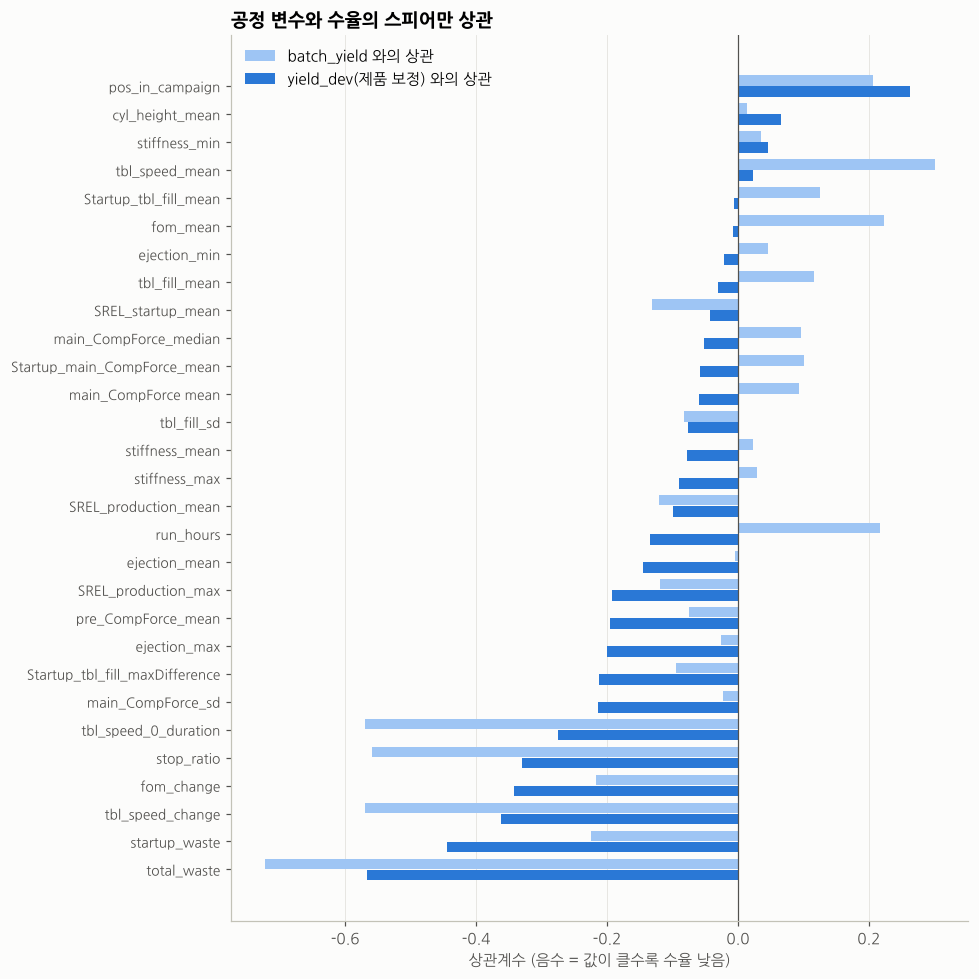

In [29]:
PROC_VARS = proc_feats + ["stop_ratio", "run_hours", "pos_in_campaign"]
PROC_VARS = [c for c in PROC_VARS if c != "weekend"]

corr = pd.DataFrame({
    "batch_yield": df[PROC_VARS].corrwith(df.batch_yield, method="spearman"),
    "yield_dev": df[PROC_VARS].corrwith(df.yield_dev, method="spearman"),
}).sort_values("yield_dev")

fig, ax = plt.subplots(figsize=(9, 9))
y = np.arange(len(corr))
ax.barh(y + 0.2, corr.batch_yield, height=0.38, color="#9ec5f4", label="batch_yield 와의 상관")
ax.barh(y - 0.2, corr.yield_dev, height=0.38, color=C_NORMAL, label="yield_dev(제품 보정) 와의 상관")
ax.set_yticks(y, corr.index, fontsize=9)
ax.axvline(0, color=C_TEXT2, lw=0.8)
ax.set(title="공정 변수와 수율의 스피어만 상관", xlabel="상관계수 (음수 = 값이 클수록 수율 낮음)")
ax.legend(loc="upper left")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

> **해석**
>
> - **값이 클수록 수율이 낮은 변수 (제품 보정 후에도 유지)**
>   - `total_waste`: 수율을 직접 깎는 값이므로 당연한 결과(증상).
>   - `startup_waste`(시작 단계 폐기): 수율 자체와는 약하지만(−0.23), **같은 제품 안에서는 강하게(−0.45)** 연결됩니다.
>     큰 배치는 시작 폐기가 많지만 수율도 높기 때문에, 제품을 섞어 보면 효과가 가려집니다.
>   - 속도 변경 횟수, 충전 장치 속도 변경, 정지 시간·비율.
> - **제품 효과였던 변수**: `tbl_speed_mean`, `fom_mean` 은 수율 자체와는 양의 상관이 있지만 제품 보정 후에는 0에 가깝습니다.
>   고속(120)으로 운전하는 10·20 mg 제품이 원래 수율이 높을 뿐, 속도 자체의 효과는 아닙니다.
> - `pos_in_campaign` 은 제품 보정 후 +0.26: 캠페인 뒤쪽 배치일수록 수율이 높습니다(6장과 일치).
> - 압축력·충전 깊이·배출력 같은 **공정 조건 자체**의 상관은 대부분 |ρ| < 0.2로 약합니다.
>   → 수율 저하는 "조건 설정"보다 **"운전 중 끊김(정지·변경·셋업)"** 과 관련이 큽니다.

### 7.2 저수율 vs 정상 배치 비교 (효과 크기)

각 변수의 그룹별 중앙값과 **클리프 델타(Cliff's δ)** 를 계산합니다.

- 클리프 δ: 저수율 배치에서 무작위로 뽑은 값이 정상 배치의 값보다 클 확률 − 작을 확률. 범위 −1 ~ +1.
- 해석 기준(관례): |δ| < 0.15 무시 가능, < 0.33 작음, < 0.47 중간, 그 이상 큼.

In [30]:
def cliffs_delta(a, b):
    # a 가 b 보다 큰 정도. Mann-Whitney U 로 계산한다.
    a, b = np.asarray(a.dropna()), np.asarray(b.dropna())
    u = stats.mannwhitneyu(a, b).statistic
    return 2 * u / (len(a) * len(b)) - 1


def compare_groups(cols, data=None):
    data = df if data is None else data
    low, nor = data[data.is_low], data[~data.is_low]
    rows = []
    for c in cols:
        rows.append({
            "변수": c,
            "정상 중앙값": nor[c].median(),
            "저수율 중앙값": low[c].median(),
            "클리프 δ": cliffs_delta(low[c], nor[c]),
            "p값": stats.mannwhitneyu(low[c].dropna(), nor[c].dropna()).pvalue,
        })
    out = pd.DataFrame(rows).set_index("변수")
    out["효과 크기"] = pd.cut(out["클리프 δ"].abs(), [0, 0.147, 0.33, 0.474, 1], labels=["무시", "작음", "중간", "큼"], include_lowest=True)
    return out.reindex(out["클리프 δ"].abs().sort_values(ascending=False).index)


cmp_proc = compare_groups(PROC_VARS)
cmp_proc.head(15).style.format({"정상 중앙값": "{:,.3f}", "저수율 중앙값": "{:,.3f}", "클리프 δ": "{:+.2f}", "p값": "{:.1e}"}) \
    .background_gradient(subset=["클리프 δ"], cmap="RdBu_r", vmin=-1, vmax=1)

,정상 중앙값,저수율 중앙값,클리프 δ,p값,효과 크기
변수,,,,,
total_waste,705.000,"1,686.667",+0.73,3.3e-31,큼
tbl_speed_0_duration,44.167,115.417,+0.68,6.6e-27,큼
stop_ratio,0.131,0.263,+0.63,1.7e-23,큼
tbl_speed_change,2.448,5.661,+0.63,2.0e-23,큼
tbl_speed_mean,119.945,99.945,-0.47,5.8e-14,큼
fom_mean,79.943,49.962,-0.33,1.9e-07,작음
pos_in_campaign,4.000,2.000,-0.28,9.3e-06,작음
run_hours,9.022,5.675,-0.28,1.2e-05,작음
SREL_startup_mean,5.948,7.054,+0.26,4.9e-05,작음


> **해석**
>
> - 효과가 **큰** 변수는 모두 **정지·속도 변경** 계열입니다.
>   - 정지 누적 시간: 저수율 115 vs 정상 44 (10만 정당, 약 2.6배)
>   - 기록 시간 중 정지 비율: 26% vs 13%
>   - 속도 변경 횟수: 5.7 vs 2.4 (10만 정당)
> - `tbl_speed_mean` 이 저수율에서 낮은 것(100 vs 120)은 7.1절대로 **제품 구성 차이**입니다. 운전 속도 중앙값은 10·20 mg이 120, 5 mg이 100, 40 mg이 80입니다.
> - SREL(압축력 변동), 충전 깊이 변동은 효과가 '작음' 수준입니다. 공정이 다소 불안정하긴 하지만 주요 원인은 아닙니다.

### 7.3 메커니즘: 정지·속도 변경 → 폐기 증가 → 수율 저하

`total_waste` 는 수율을 직접 깎는 값(증상)입니다. 그렇다면 **무엇이 폐기를 늘리는가**를 봅니다.
각 변수를 4개 구간(사분위)으로 나누어 구간별 저수율 비율을 비교합니다.

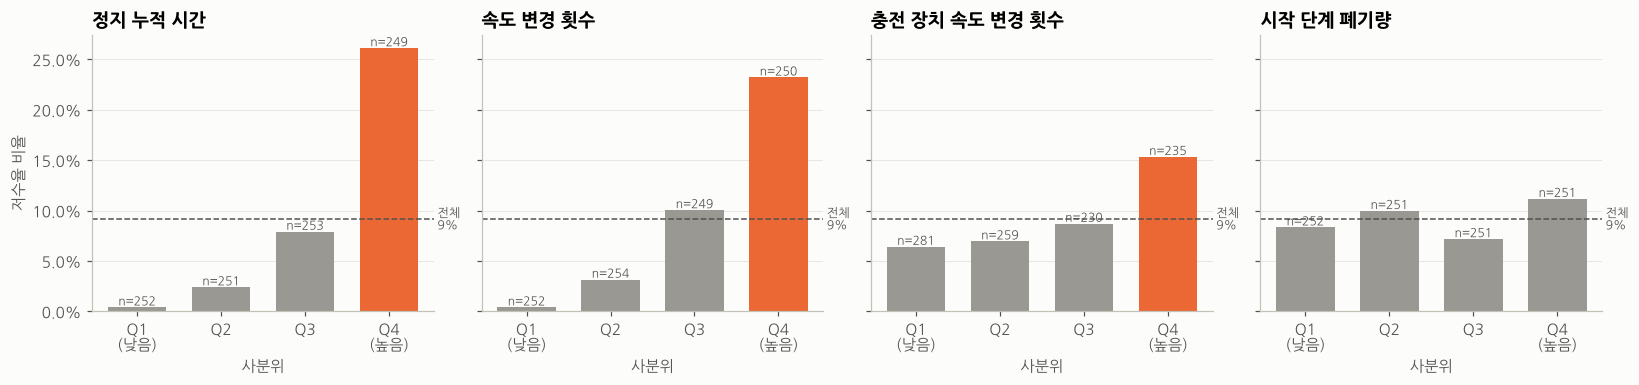

In [31]:
quart_vars = {
    "tbl_speed_0_duration": "정지 누적 시간",
    "tbl_speed_change": "속도 변경 횟수",
    "fom_change": "충전 장치 속도 변경 횟수",
    "startup_waste": "시작 단계 폐기량",
}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (c, label) in zip(axes, quart_vars.items()):
    q = pd.qcut(df[c], 4, labels=["Q1\n(낮음)", "Q2", "Q3", "Q4\n(높음)"])
    t = seg_table(q)
    plot_low_rate(t, label, "사분위", ax=ax)
    ax.set_ylabel("저수율 비율" if ax is axes[0] else "")
plt.tight_layout()
plt.show()

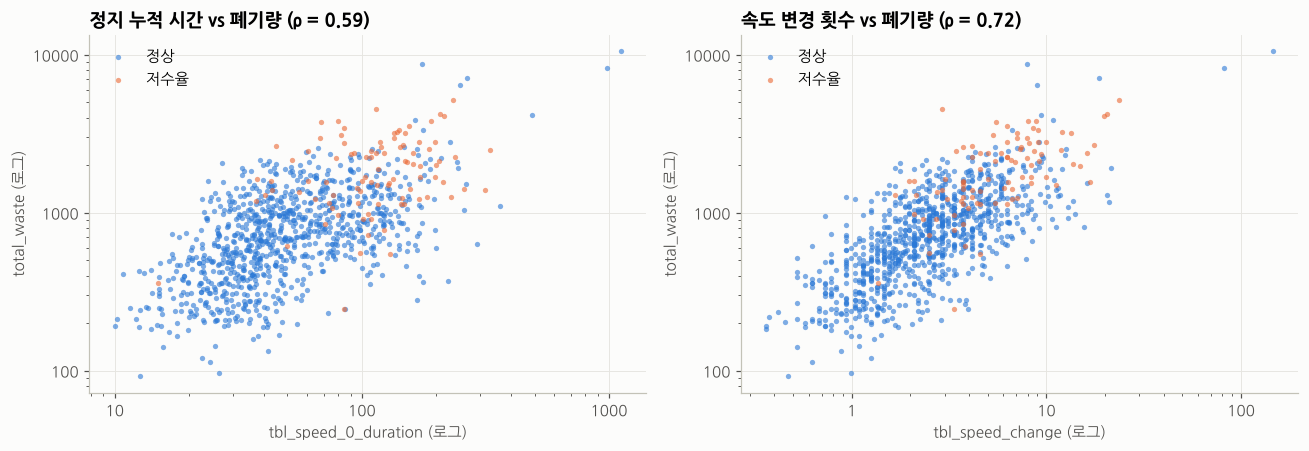

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, x in zip(axes, ["tbl_speed_0_duration", "tbl_speed_change"]):
    for g in ["정상", "저수율"]:
        d = df[df.group == g]
        ax.scatter(d[x], d.total_waste, s=12, alpha=0.6, color=PALETTE[g], label=g, linewidths=0)
    rho = stats.spearmanr(df[x], df.total_waste)[0]
    ax.set(xscale="log", yscale="log", xlabel=f"{x} (로그)", ylabel="total_waste (로그)",
           title=f"{quart_vars[x]} vs 폐기량 (ρ = {rho:.2f})")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.legend()
plt.tight_layout()
plt.show()

> **해석**
>
> - 정지 시간과 속도 변경 횟수는 **용량-반응 관계**를 보입니다. 하위 25%(Q1) 배치의 저수율 비율은 0.4%,
>   상위 25%(Q4)는 23~26%입니다.
> - 두 변수 모두 폐기량과 강하게 연결됩니다(ρ = 0.59, 0.72). 정리하면 **정지·속도 변경 → 재시작 시 불량 배출 → 폐기 증가 → 수율 저하** 의 흐름이 데이터와 맞습니다(9장에서 시계열로 확인).
> - 시작 단계 폐기량은 전체로 보면 사분위별 차이가 거의 없습니다. 7.1절에서 본 것처럼 **배치 크기와 섞여 있기 때문**이며,
>   제품 내에서 비교하면 강한 요인입니다(10.2절).
> - ⚠️ 정지 시간은 "10만 정당"으로 정규화된 값이라, 고정된 셋업 정지 시간도 **소형 배치에서는 크게 계산됩니다**
>   (배치 크기 240k의 중앙값 113 vs 1.92M의 중앙값 29). 정지 효과의 일부는 소형 배치 효과와 겹칩니다.

### 7.4 운전 변수 간 상관 (중복 확인)

비슷한 정보를 담은 변수끼리 묶어서, 시나리오를 정리할 때 같은 현상을 두 번 세지 않도록 합니다.

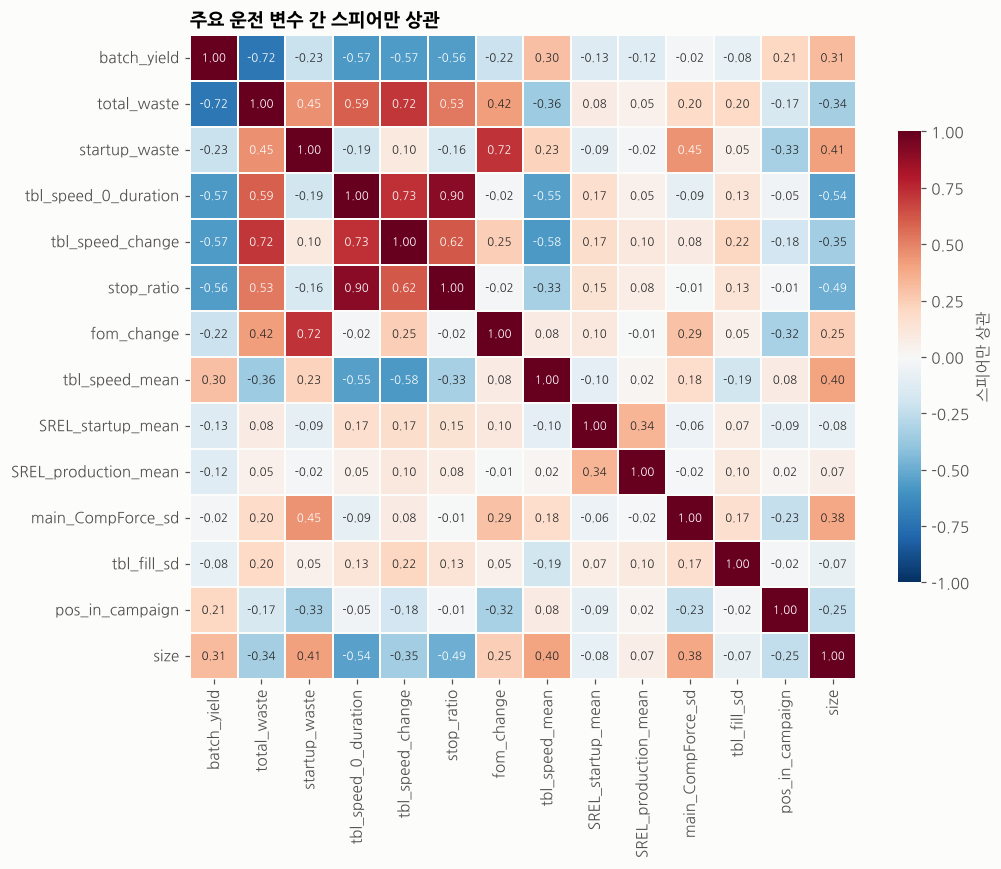

In [33]:
key_vars = ["batch_yield", "total_waste", "startup_waste", "tbl_speed_0_duration", "tbl_speed_change", "stop_ratio",
            "fom_change", "tbl_speed_mean", "SREL_startup_mean", "SREL_production_mean", "main_CompForce_sd",
            "tbl_fill_sd", "pos_in_campaign", "size"]
cm = df[key_vars].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(cm, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 7.5},
            linewidths=1, linecolor="#fcfcfb", cbar_kws={"shrink": 0.7, "label": "스피어만 상관"}, ax=ax)
ax.grid(False)
ax.set_title("주요 운전 변수 간 스피어만 상관")
plt.tight_layout()
plt.show()

> **해석**
>
> 변수들은 세 묶음으로 나뉩니다. 시나리오를 정리할 때 같은 묶음 안의 변수는 **같은 현상**으로 봅니다.
>
> | 묶음 | 변수 | 의미 |
> |---|---|---|
> | 정지·재시작 | `tbl_speed_0_duration`, `stop_ratio`, `tbl_speed_change` (서로 0.62~0.90) | 운전 중 멈추고 다시 시작하는 일 |
> | 셋업 | `startup_waste`, `fom_change` (0.72), `main_CompForce_sd` (0.45) | 시작 단계에서 조건을 맞추는 일 |
> | 압축 안정성 | `SREL_*` | 다른 변수와 거의 독립, 수율과도 약함 |
>
> 또 `size` 는 정지 계열과 음의 상관(−0.54)이 있어, 7.3절의 주의점(정규화로 인한 소형 배치 효과)을 다시 확인할 수 있습니다.

---
## 8. 원자재·품질 검사 변수와 수율

### 8.1 원자재 물성

API·부형제의 물성 측정값과 수율의 관계를 봅니다. 제품 효과를 걸러낸 `yield_dev` 와의 상관도 함께 봅니다.

In [34]:
RAW_VARS = ["api_water", "api_total_impurities", "api_l_impurity", "api_content", "api_ps01", "api_ps05", "api_ps09",
            "lactose_water", "lactose_sieve0045", "lactose_sieve015", "lactose_sieve025",
            "smcc_water", "smcc_td", "smcc_bd", "smcc_ps01", "smcc_ps05", "smcc_ps09", "starch_ph", "starch_water"]

raw_corr = pd.DataFrame({
    "batch_yield ρ": df[RAW_VARS].corrwith(df.batch_yield, method="spearman"),
    "yield_dev ρ": df[RAW_VARS].corrwith(df.yield_dev, method="spearman"),
})
raw_cmp = compare_groups(RAW_VARS)[["클리프 δ", "효과 크기"]]
raw_corr.join(raw_cmp).sort_values("yield_dev ρ").style.format({"batch_yield ρ": "{:+.2f}", "yield_dev ρ": "{:+.2f}", "클리프 δ": "{:+.2f}"}) \
    .background_gradient(subset=["batch_yield ρ", "yield_dev ρ"], cmap="RdBu_r", vmin=-0.5, vmax=0.5)

,batch_yield ρ,yield_dev ρ,클리프 δ,효과 크기
lactose_sieve0045,-0.04,-0.06,+0.09,무시
smcc_bd,-0.17,-0.05,+0.24,작음
api_content,-0.12,-0.05,-0.00,무시
api_l_impurity,+0.08,-0.05,-0.09,무시
starch_ph,-0.10,-0.05,+0.12,무시
smcc_ps01,-0.03,-0.04,-0.02,무시
api_ps01,+0.09,-0.04,-0.00,무시
api_total_impurities,+0.17,-0.04,-0.11,무시
smcc_ps05,+0.05,-0.04,-0.12,무시
smcc_water,-0.14,-0.04,+0.16,작음


> **해석**
>
> - **원자재 물성은 같은 제품 안에서 수율과 거의 관련이 없습니다.** `yield_dev` 와의 상관은 모두 |ρ| ≤ 0.08입니다.
> - `smcc_bd`, `api_total_impurities` 처럼 수율 자체와 약한 상관(±0.17)을 보이는 변수가 있지만, 제품 보정 후 사라집니다.
>   → 제품마다 쓰는 원료 규격이 달라서 생긴 **겉보기 상관**입니다.

### 8.2 원자재 로트 효과

같은 로트의 원료를 쓴 배치끼리 수율이 비슷하게 낮다면 **로트 품질 문제**를 의심할 수 있습니다.
배치 수가 5개 이상인 로트만 대상으로, 로트별 `yield_dev` 차이를 크루스칼-월리스 검정으로 확인합니다.

In [35]:
lot_rows = []
for lot in ["api_batch", "smcc_batch", "lactose_batch", "starch_batch"]:
    sizes = df.groupby(lot).size()
    keep = sizes[sizes >= 5].index
    groups = [g.yield_dev.values for _, g in df[df[lot].isin(keep)].groupby(lot)]
    h, p = stats.kruskal(*groups)
    lot_low = df[df[lot].isin(keep)].groupby(lot).is_low.mean()
    lot_rows.append({"로트": lot, "전체 로트 수": df[lot].nunique(), "5배치 이상 로트": len(keep),
                     "로트별 저수율 비율 최대": lot_low.max(), "크루스칼 H": h, "p값": p})
pd.DataFrame(lot_rows).set_index("로트").style.format({"로트별 저수율 비율 최대": "{:.0%}", "크루스칼 H": "{:.1f}", "p값": "{:.1e}"})

,전체 로트 수,5배치 이상 로트,로트별 저수율 비율 최대,크루스칼 H,p값
로트,,,,,
api_batch,238,83,50%,125.6,1.4e-03
smcc_batch,18,18,25%,62.3,4.4e-07
lactose_batch,22,22,53%,64.8,2.4e-06
starch_batch,17,17,27%,62.8,1.8e-07


In [36]:
# API 로트별 저수율 비율 상위 (5배치 이상)
api_lot = (df.groupby("api_batch")
             .agg(배치수=("is_low", "size"), 저수율_비율=("is_low", "mean"), yield_dev_중앙값=("yield_dev", "median"),
                  제품코드=("code", lambda s: sorted(s.unique())), 시작월=("start_month", "min"))
             .query("배치수 >= 5")
             .sort_values(["저수율_비율", "yield_dev_중앙값"], ascending=[False, True]))
api_lot.head(8).style.format({"저수율_비율": "{:.0%}", "yield_dev_중앙값": "{:+.2f}", "시작월": lambda d: d.strftime("%Y-%m")})

,배치수,저수율_비율,yield_dev_중앙값,제품코드,시작월
api_batch,,,,,
165,6,50%,-0.88,"[np.int64(15), np.int64(21)]",2019-06
14,6,50%,+0.38,"[np.int64(9), np.int64(11)]",2019-01
10,11,45%,-1.09,"[np.int64(1), np.int64(3)]",2018-11
67,5,40%,+0.00,"[np.int64(9), np.int64(12)]",2019-08
20,11,36%,-0.76,[np.int64(25)],2019-02
119,12,25%,-0.14,"[np.int64(17), np.int64(21), np.int64(22), np.int64(23)]",2018-11
163,21,24%,-0.14,"[np.int64(15), np.int64(21), np.int64(23)]",2019-04
170,24,21%,-0.02,"[np.int64(17), np.int64(21), np.int64(23)]",2019-05


> **해석**
>
> - 로트별 `yield_dev` 차이는 통계적으로 유의합니다(p < 0.01). 하지만 이것만으로 "로트 품질 문제"라고 결론 내릴 수는 없습니다.
>   **로트는 특정 시기에 특정 제품에만 쓰이기 때문에**, 로트 효과는 시기 효과(5.3절)·캠페인 효과(6장)와 섞여 있습니다.
> - 8.1절에서 측정된 물성으로는 차이가 설명되지 않았다는 점도 같이 봐야 합니다.
> - 확인할 후보: API 로트 10(제품 1·3번, 2018-11, 저수율 45%), 165(제품 15·21번, 2019-06), 20(제품 25번, 2019-02).
>   이 로트들이 쓰인 시기의 생산 기록과 대조하면 로트 문제인지 운전 문제인지 가릴 수 있습니다.

### 8.3 공정 중 검사(IPC)와 출하 품질

정제 물성(IPC)과 출하 품질이 수율과 함께 움직이는지 봅니다.
수율이 낮은 배치가 품질도 나쁜지(같은 문제의 두 얼굴), 아니면 품질과는 무관한지 확인하는 목적입니다.

In [37]:
IPC_VARS = ["tbl_rsd_weight", "fct_rsd_weight", "tbl_av_hardness", "fct_av_hardness", "tbl_tensile", "fct_tensile",
            "tbl_min_weight", "tbl_max_weight"]
QUAL_VARS = ["dissolution_av", "dissolution_min", "resodual_solvent", "impurities_total", "impurity_o", "impurity_l"]

iq = pd.DataFrame({
    "구분": ["IPC"] * len(IPC_VARS) + ["출하 품질"] * len(QUAL_VARS),
    "batch_yield ρ": df[IPC_VARS + QUAL_VARS].corrwith(df.batch_yield, method="spearman").values,
    "yield_dev ρ": df[IPC_VARS + QUAL_VARS].corrwith(df.yield_dev, method="spearman").values,
}, index=IPC_VARS + QUAL_VARS)
iq.join(compare_groups(IPC_VARS + QUAL_VARS)[["정상 중앙값", "저수율 중앙값", "클리프 δ"]]) \
  .style.format({"batch_yield ρ": "{:+.2f}", "yield_dev ρ": "{:+.2f}", "클리프 δ": "{:+.2f}", "정상 중앙값": "{:.3f}", "저수율 중앙값": "{:.3f}"}) \
  .background_gradient(subset=["batch_yield ρ", "yield_dev ρ"], cmap="RdBu_r", vmin=-0.5, vmax=0.5)

,구분,batch_yield ρ,yield_dev ρ,정상 중앙값,저수율 중앙값,클리프 δ
tbl_rsd_weight,IPC,-0.16,-0.18,0.960,1.175,+0.38
fct_rsd_weight,IPC,-0.06,-0.10,0.950,1.030,+0.18
tbl_av_hardness,IPC,+0.14,+0.03,52.000,51.000,-0.14
fct_av_hardness,IPC,+0.16,+0.00,68.600,64.680,-0.23
tbl_tensile,IPC,-0.08,+0.02,1.142,1.434,+0.19
fct_tensile,IPC,-0.07,+0.00,1.560,1.806,+0.13
tbl_min_weight,IPC,+0.19,+0.04,220.000,111.000,-0.27
tbl_max_weight,IPC,+0.15,-0.01,228.000,115.000,-0.16
dissolution_av,출하 품질,-0.19,-0.04,90.170,92.830,+0.34
dissolution_min,출하 품질,-0.20,-0.05,85.000,88.000,+0.35


> **해석**
>
> - **정제 무게 변동(`tbl_rsd_weight`)** 만 제품 보정 후에도 수율과 관련이 있습니다(저수율 1.18% vs 정상 0.96%, δ = +0.38).
>   무게가 들쭉날쭉하면 무게 기준을 벗어난 정제가 자동 배출되어 폐기가 늘어나는 것과 맞는 결과입니다.
> - 무게·경도·용출률의 그룹 차이는 대부분 **제품 구성 차이**입니다. 예를 들어 저수율 그룹의 정제 무게 중앙값이 111 mg으로
>   정상(220 mg)의 절반인 것은 5 mg 제품(가벼운 정제)이 많기 때문입니다.
> - **출하 품질(용출·불순물)은 저수율 배치에서도 나빠지지 않습니다.** 수율 저하는 품질 문제라기보다
>   **생산성(손실) 문제**로 보는 것이 맞습니다.

---
## 9. 시계열 심층 비교

배치 요약값만으로는 "언제, 어떻게" 손실이 생기는지 알 수 없습니다.
같은 제품 안에서 **저수율 배치와 대표 정상 배치**의 10초 단위 시계열을 나란히 비교합니다.

- 시간 축: 3.4절의 날짜 문제를 피하기 위해 **배치 시작 후 경과 시간(= 샘플 순서 × 10초)** 을 씁니다.
- 폐기 카운터(`waste`)는 중간에 0으로 리셋되기도 하므로, **증가분만 누적**해 리셋에 영향받지 않는 누적 폐기량을 만듭니다.

### 9.1 비교 배치 선정

배치 수가 가장 많은 제품 17번(20 mg, 960k)에서 다음 두 배치를 고릅니다.

- 저수율: 제품 17번에서 수율이 가장 낮은 배치
- 정상: 제품 17번의 수율 중앙값에 가장 가까우면서 캠페인 2번째 이후인 배치

In [38]:
CODE = 17
d17 = df[df.code == CODE]
low_b = d17.batch_yield.idxmin()
normal_pool = d17[~d17.first_in_campaign]
normal_b = (normal_pool.batch_yield - d17.batch_yield.median()).abs().idxmin()

show_cols = ["batch_yield", "tbl_yield", "pos_in_campaign", "is_weekend", "startup_waste", "total_waste",
             "tbl_speed_0_duration", "tbl_speed_change", "run_hours"]
df.loc[[normal_b, low_b], show_cols].rename(index={normal_b: f"정상 (배치 {normal_b})", low_b: f"저수율 (배치 {low_b})"}).T

batch,정상 (배치 707),저수율 (배치 789)
batch_yield,98.769,87.973
tbl_yield,98.582,87.973
pos_in_campaign,4,7
is_weekend,False,False
startup_waste,2677,78
total_waste,303.542,"4,552.812"
tbl_speed_0_duration,57.500,114.583
tbl_speed_change,2.604,2.917
run_hours,9.561,6.367


### 9.2 속도·누적 폐기량 궤적

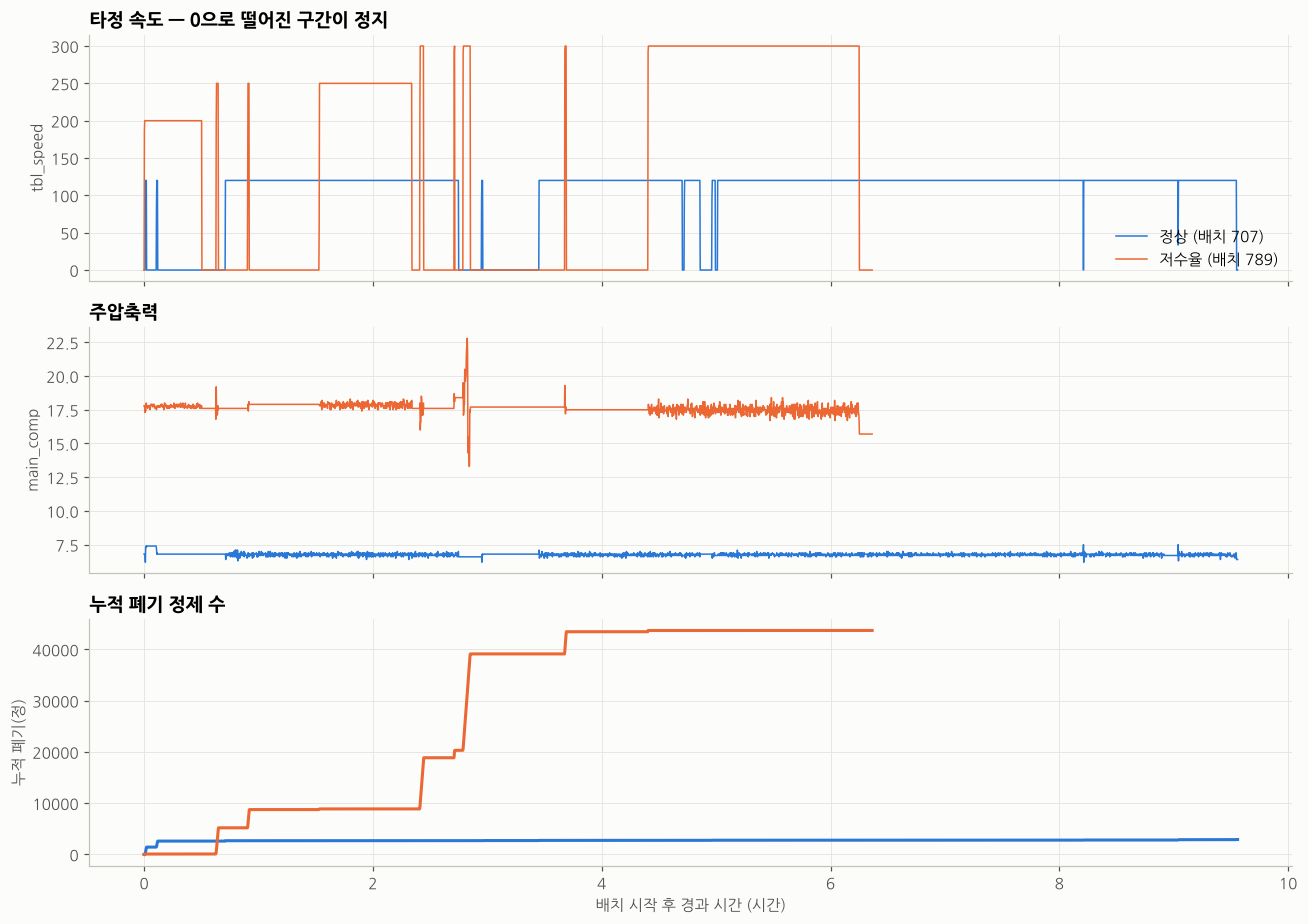

In [39]:
raw17 = read_ts(CODE)


def batch_trace(b):
    d = raw17[raw17.batch == b].reset_index(drop=True).copy()
    d["hours"] = d.index * 10 / 3600
    d["waste_cum"] = d.waste.diff().clip(lower=0).fillna(0).cumsum()   # 리셋에 강한 누적 폐기량
    return d


traces = {"정상": batch_trace(normal_b), "저수율": batch_trace(low_b)}

fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True)
for g, d in traces.items():
    axes[0].plot(d.hours, d.tbl_speed, lw=1, color=PALETTE[g], label=f"{g} (배치 {d.batch.iat[0]})")
    axes[1].plot(d.hours, d.main_comp, lw=1, color=PALETTE[g])
    axes[2].plot(d.hours, d.waste_cum, lw=2, color=PALETTE[g])
axes[0].set(title="타정 속도 — 0으로 떨어진 구간이 정지", ylabel="tbl_speed")
axes[1].set(title="주압축력", ylabel="main_comp")
axes[2].set(title="누적 폐기 정제 수", ylabel="누적 폐기(정)", xlabel="배치 시작 후 경과 시간 (시간)")
axes[0].legend(loc="lower right")
plt.tight_layout()
plt.show()

In [40]:
def stop_events(d):
    # 정지(속도 0) 구간의 횟수와 길이
    stopped = d.tbl_speed.eq(0)
    run_id = (stopped != stopped.shift()).cumsum()
    lens = stopped.groupby(run_id).agg(["first", "size"]).query("first")["size"] * 10 / 60
    return pd.Series({"정지 횟수": len(lens), "정지 총 시간(분)": lens.sum(), "가장 긴 정지(분)": lens.max(),
                      "기록 길이(시간)": len(d) * 10 / 3600, "누적 폐기(정)": d.waste_cum.iat[-1]})


pd.DataFrame({g: stop_events(d) for g, d in traces.items()}).style.format("{:,.1f}")

,정상,저수율
정지 횟수,10.0,10.0
정지 총 시간(분),92.0,183.3
가장 긴 정지(분),35.5,49.5
기록 길이(시간),9.6,6.4
누적 폐기(정),"2,914.0","43,707.0"


### 9.3 제품 17번 전체: 정지 횟수와 수율

두 배치의 차이가 우연이 아닌지, 제품 17번의 모든 배치(207개)로 확인합니다.

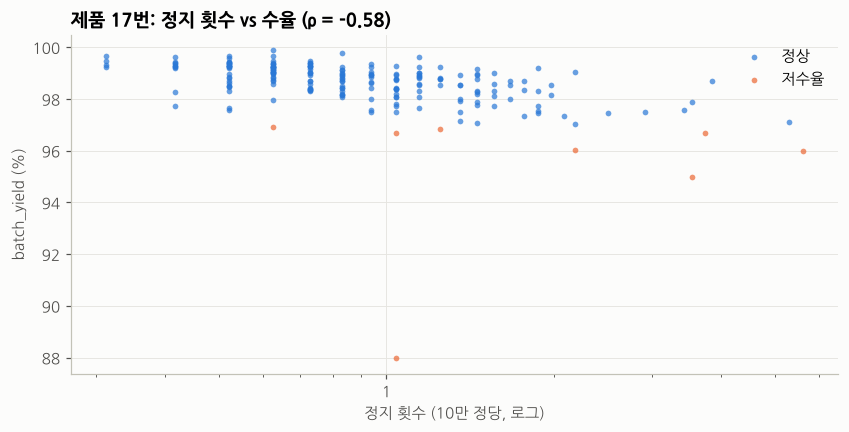

In [41]:
raw17["stopped"] = raw17.tbl_speed.eq(0)
raw17["stop_start"] = raw17.stopped & ~raw17.groupby("batch").stopped.shift(fill_value=False)
ev17 = raw17.groupby("batch").agg(정지횟수=("stop_start", "sum"))
ev17 = ev17.join(df[["batch_yield", "is_low", "group", "size"]])
ev17["정지횟수_10만정당"] = ev17.정지횟수 / (ev17["size"] / 1e5)

fig, ax = plt.subplots(figsize=(9, 4))
for g in ["정상", "저수율"]:
    d = ev17[ev17.group == g]
    ax.scatter(d.정지횟수_10만정당, d.batch_yield, s=14, alpha=0.7, color=PALETTE[g], label=g, linewidths=0)
rho = stats.spearmanr(ev17.정지횟수_10만정당, ev17.batch_yield)[0]
ax.set(xscale="log", xlabel="정지 횟수 (10만 정당, 로그)", ylabel="batch_yield (%)",
       title=f"제품 17번: 정지 횟수 vs 수율 (ρ = {rho:.2f})")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(mtick.NullFormatter())
ax.legend()
plt.show()

> **해석**
>
> **배치 789 vs 배치 707 (같은 제품 17번)**
>
> - 저수율 배치 789(수율 88.0%, 전체 최저)는 **같은 제품인데 운전 조건이 전혀 다릅니다.**
>   속도는 200~300(정상 120), 주압축력은 약 17.5(정상 약 7)입니다.
>   제품 17번 배치의 속도 평균은 대부분 120, 높아야 160인데 789만 272로 튀므로 **반복되는 패턴이 아니라 단발성 이상 운전**입니다
>   (시험 생산이나 설정 오류 가능성 — 생산 기록 확인 필요).
> - 누적 폐기량 그래프를 보면 폐기가 **꾸준히 늘지 않고 계단처럼 뜁니다.** 계단이 생기는 시점은 대부분 속도가 0에서 다시 올라가는 **재시작 시점**과 겹칩니다.
> - 두 배치의 정지 횟수는 10회로 같지만, 정지 총 시간은 저수율 배치가 2배(183분 vs 92분)이고 폐기량은 15배(43,707 vs 2,914정)입니다.
>   → 정지 그 자체보다 **"재시작할 때 조건이 안정되기까지 버려지는 정제"** 가 손실의 핵심으로 보입니다.
>
> **제품 17번 전체(207개 배치)**
>
> - 10만 정당 정지 횟수와 수율의 상관은 ρ = −0.58로, 같은 제품 안에서도 정지가 잦을수록 수율이 분명히 낮습니다.

---
## 10. 수율 저하 시나리오 종합

### 10.1 의사결정나무로 규칙 확인

지금까지 찾은 요인을 함께 넣었을 때 **어떤 조합이 저수율을 가장 잘 가르는지** 얕은 의사결정나무(깊이 3)로 확인합니다.
예측 모델이 아니라 **사람이 읽을 수 있는 규칙**을 얻기 위한 것입니다.

- 입력: 구조적 요인(배치 크기, 함량, 캠페인 첫 배치, 주말) + 운전 요인(정지, 속도 변경, 시작 단계 손실 등)
- 제외: `total_waste`, `tbl_yield` (수율과 거의 같은 정보이므로 규칙이 의미 없어짐)

In [42]:
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score

TREE_VARS = ["size", "strength_mg", "first_in_campaign", "is_weekend", "tbl_speed_0_duration", "tbl_speed_change",
             "fom_change", "startup_waste", "SREL_startup_mean", "tbl_speed_mean", "main_CompForce_sd"]
df["strength_mg"] = df.strength.map({"5MG": 5, "10M": 10, "20M": 20, "40M": 40}).astype(int)
X, y = df[TREE_VARS].astype(float), df.is_low

tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight="balanced", random_state=0).fit(X, y)
auc = cross_val_score(DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight="balanced", random_state=0),
                      X, y, cv=5, scoring="roc_auc")
print(f"5겹 교차검증 ROC-AUC: {auc.mean():.2f} ± {auc.std():.2f}  (0.5 = 무작위)\n")
print(export_text(tree, feature_names=TREE_VARS, decimals=1))

5겹 교차검증 ROC-AUC: 0.79 ± 0.09  (0.5 = 무작위)

|--- tbl_speed_0_duration <= 67.8
|   |--- startup_waste <= 11455.5
|   |   |--- tbl_speed_0_duration <= 60.4
|   |   |   |--- class: False
|   |   |--- tbl_speed_0_duration >  60.4
|   |   |   |--- class: False
|   |--- startup_waste >  11455.5
|   |   |--- tbl_speed_0_duration <= 36.9
|   |   |   |--- class: False
|   |   |--- tbl_speed_0_duration >  36.9
|   |   |   |--- class: True
|--- tbl_speed_0_duration >  67.8
|   |--- startup_waste <= 2119.0
|   |   |--- tbl_speed_mean <= 99.9
|   |   |   |--- class: True
|   |   |--- tbl_speed_mean >  99.9
|   |   |   |--- class: False
|   |--- startup_waste >  2119.0
|   |   |--- tbl_speed_mean <= 119.9
|   |   |   |--- class: True
|   |   |--- tbl_speed_mean >  119.9
|   |   |   |--- class: False



In [43]:
# 잎(leaf)별 실제 저수율 비율 — 규칙을 사람이 읽을 수 있게 정리
leaf = tree.apply(X)
leaf_tbl = (df.assign(leaf=leaf).groupby("leaf")
              .agg(배치수=("is_low", "size"), 저수율_배치=("is_low", "sum"), 저수율_비율=("is_low", "mean"),
                   수율_중앙값=("batch_yield", "median"))
              .sort_values("저수율_비율", ascending=False))
leaf_tbl["전체 저수율 중 비중"] = leaf_tbl.저수율_배치 / df.is_low.sum()

# 각 잎에 이르는 규칙 문자열
t = tree.tree_
def path_rules(node_id):
    rules, node = [], 0
    target_path = tree.decision_path(X.iloc[[np.where(leaf == node_id)[0][0]]]).indices
    for n in target_path[:-1]:
        f, thr = TREE_VARS[t.feature[n]], t.threshold[n]
        go_left = X.iloc[np.where(leaf == node_id)[0][0]][f] <= thr
        rules.append(f"{f} {'≤' if go_left else '>'} {thr:,.1f}")
    return "  &  ".join(rules)

leaf_tbl.insert(0, "규칙", [path_rules(i) for i in leaf_tbl.index])
leaf_tbl.style.format({"저수율_비율": "{:.0%}", "수율_중앙값": "{:.2f}", "전체 저수율 중 비중": "{:.0%}"}).hide(axis="index")

규칙,배치수,저수율_배치,저수율_비율,수율_중앙값,전체 저수율 중 비중
"tbl_speed_0_duration > 67.8 & startup_waste > 2,119.0 & tbl_speed_mean ≤ 119.9",185,68,37%,97.35,74%
"tbl_speed_0_duration ≤ 67.8 & startup_waste > 11,455.5 & tbl_speed_0_duration > 36.9",53,8,15%,97.73,9%
"tbl_speed_0_duration > 67.8 & startup_waste ≤ 2,119.0 & tbl_speed_mean ≤ 99.9",43,6,14%,98.11,7%
"tbl_speed_0_duration > 67.8 & startup_waste > 2,119.0 & tbl_speed_mean > 119.9",53,4,8%,97.92,4%
"tbl_speed_0_duration ≤ 67.8 & startup_waste ≤ 11,455.5 & tbl_speed_0_duration > 60.4",36,2,6%,98.33,2%
"tbl_speed_0_duration > 67.8 & startup_waste ≤ 2,119.0 & tbl_speed_mean > 99.9",66,1,2%,98.11,1%
"tbl_speed_0_duration ≤ 67.8 & startup_waste ≤ 11,455.5 & tbl_speed_0_duration ≤ 60.4",547,3,1%,98.91,3%
"tbl_speed_0_duration ≤ 67.8 & startup_waste > 11,455.5 & tbl_speed_0_duration ≤ 36.9",22,0,0%,97.95,0%


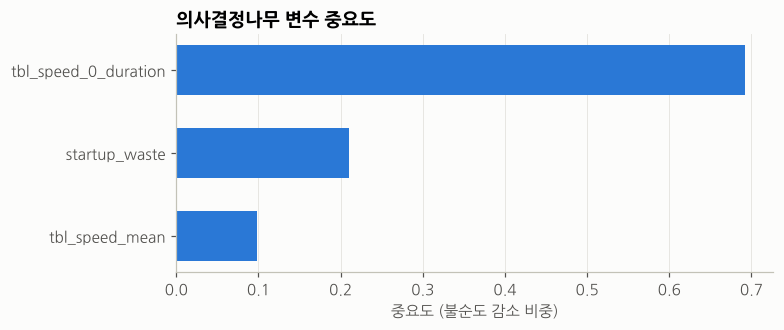

In [44]:
imp = pd.Series(tree.feature_importances_, index=TREE_VARS).sort_values()
imp = imp[imp > 0]
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(imp.index, imp.values, color=C_NORMAL, height=0.6)
ax.set(title="의사결정나무 변수 중요도", xlabel="중요도 (불순도 감소 비중)")
ax.grid(axis="y", visible=False)
plt.show()

> **해석**
>
> - 얕은 나무(깊이 3)만으로도 교차검증 ROC-AUC 0.79로 저수율 배치를 꽤 잘 구분합니다.
> - 나무가 고른 변수는 **정지 시간 → 시작 단계 폐기량 → 평균 속도** 순입니다.
> - 가장 위험한 규칙: **정지 시간 > 67.8 & 시작 단계 폐기량 > 2,119 & 평균 속도 ≤ 119.9**
>   → 185개 배치 중 37%가 저수율이며, **전체 저수율 배치의 74%가 이 잎에 들어 있습니다.**
> - 가장 안전한 규칙: 정지 시간 ≤ 60.4 & 시작 단계 폐기량 ≤ 11,456 → 547개 배치 중 저수율은 1%.
> - 배치 크기·함량·캠페인 첫 배치는 직접 선택되지 않았습니다. 정지 시간(10만 정당)과 시작 단계 폐기량이
>   이미 그 정보를 담고 있기 때문입니다(7.3·7.4절). 즉 **구조적 요인은 운전 지표를 통해 수율에 나타납니다.**

### 10.2 수율 저하 시나리오 요약

앞 장에서 찾은 조건을 **배치 플래그**로 만들고, 각 조건에 해당하는 배치의 저수율 비율과
**리프트**(저수율 비율 ÷ 전체 저수율 비율)를 계산합니다.

In [45]:
q75_by_code = df.groupby("code").startup_waste.transform(lambda s: s.quantile(0.75))
flags = {
    "S1 정지 시간 상위 25%": df.tbl_speed_0_duration > df.tbl_speed_0_duration.quantile(0.75),
    "S1 속도 변경 상위 25%": df.tbl_speed_change > df.tbl_speed_change.quantile(0.75),
    "S2 캠페인 첫 배치": df.first_in_campaign,
    "S2 시작 단계 폐기량 상위 25% (제품 내)": df.startup_waste > q75_by_code,
    "S3 소형 배치 (≤600k)": df["size"] <= 600_000,
    "S4 주말 생산": df.is_weekend,
    "S2 + S3 소형 배치의 첫 배치": df.first_in_campaign & (df["size"] <= 600_000),
    "S1 + S2 첫 배치 & 정지 시간 상위 25%": df.first_in_campaign & (df.tbl_speed_0_duration > df.tbl_speed_0_duration.quantile(0.75)),
}
any_flag = pd.concat([flags["S1 정지 시간 상위 25%"], flags["S2 캠페인 첫 배치"], flags["S3 소형 배치 (≤600k)"]], axis=1).any(axis=1)
flags["(참고) S1·S2·S3 어디에도 해당 없음"] = ~any_flag

sc = pd.DataFrame([
    {"조건": k, "배치수": int(m.sum()), "저수율 비율": df.loc[m, "is_low"].mean(),
     "리프트": df.loc[m, "is_low"].mean() / OVERALL_LOW, "전체 저수율 중 비중": df.loc[m, "is_low"].sum() / df.is_low.sum()}
    for k, m in flags.items()
]).set_index("조건")
sc.style.format({"저수율 비율": "{:.1%}", "리프트": "{:.1f}배", "전체 저수율 중 비중": "{:.0%}"}) \
  .bar(subset=["리프트"], color="#fbd3c2", vmin=0)

,배치수,저수율 비율,리프트,전체 저수율 중 비중
조건,,,,
S1 정지 시간 상위 25%,249,26.1%,2.9배,71%
S1 속도 변경 상위 25%,250,23.2%,2.5배,63%
S2 캠페인 첫 배치,187,20.3%,2.2배,41%
S2 시작 단계 폐기량 상위 25% (제품 내),255,20.8%,2.3배,58%
S3 소형 배치 (≤600k),255,23.1%,2.5배,64%
S4 주말 생산,55,18.2%,2.0배,11%
S2 + S3 소형 배치의 첫 배치,36,66.7%,7.3배,26%
S1 + S2 첫 배치 & 정지 시간 상위 25%,52,51.9%,5.7배,29%
(참고) S1·S2·S3 어디에도 해당 없음,558,2.0%,0.2배,12%


> **해석**
>
> - S1·S2·S3 중 **어느 것에도 해당하지 않는 배치(558개)의 저수율 비율은 2%** 에 불과합니다. 저수율 배치의 88%는 이 세 시나리오 중 하나 이상에 해당합니다.
> - 조건이 겹치면 위험이 크게 커집니다. **소형 배치의 첫 배치는 3개 중 2개(67%)가 저수율**이고(리프트 7.3배), 첫 배치이면서 정지가 많은 배치도 절반 이상(52%)이 저수율입니다.

#### 수율 저하 시나리오 정리

| # | 시나리오 | 무엇이 일어나는가 (가설) | 핵심 근거 | 유형 |
|---|---|---|---|---|
| **S1** | **잦은·긴 정지와 재시작** | 운전이 멈췄다 다시 시작할 때마다 조건이 안정될 때까지 불량 정제가 배출되어 폐기가 계단식으로 쌓인다 | 정지 시간 상위 25% 배치의 저수율 26%(Q1은 0.4%) · 클리프 δ 0.68 · 시계열에서 재시작마다 폐기 급증 · 의사결정나무 1순위 | 운전 |
| **S2** | **캠페인 첫 배치 (제품 교체 직후)** | 제품 교체 후 셋업 과정의 폐기가 첫 배치에 집중된다 | 첫 배치 저수율 20%(4번째 이후 6%) · 시작 단계 폐기량 약 2배 · 모든 함량에서 동일 | 구조 + 운전 |
| **S3** | **소형 배치 (≤ 600k, 주로 5 mg)** | 셋업·재시작 손실은 거의 고정인데 분모(배치 크기)가 작아 수율이 크게 깎인다 | 소형 배치 저수율 23% · 같은 함량 안에서도 유지(5 mg 23% vs 12%, 40 mg 27% vs 8%) | 구조 |
| **S2+S3** | **소형 배치의 캠페인 첫 배치** | 위 두 효과가 겹친다 | 36개 중 67%가 저수율 (리프트 7.3배) | 복합 |
| S4 | 주말 생산 (약한 가설) | 인력·대응 속도 차이로 정지 대응이 늦어질 수 있다 | 주말 18% vs 평일 9% · 단, 함량별 표본이 6~20개뿐 | 운영 |
| 참고 | 단발성 이상 운전 | 표준과 다른 속도·압축력 설정으로 대량 폐기 | 배치 789 (수율 88%) 1건 | 이벤트 |

#### 수율 저하와 관련이 **약하거나 없는** 것

- **원자재 물성**: 제품 보정 후 상관이 모두 |ρ| ≤ 0.08 (8.1절).
- **원자재 로트**: 차이는 있지만 시기·제품과 섞여 있어 단독 원인으로 보기 어려움 (8.2절).
- **압축 조건(압축력·충전 깊이) 자체**: 상관이 약함 (7.1절).
- **출하 품질**: 저수율 배치도 품질은 나빠지지 않음 → 수율 저하는 **생산성 문제** (8.3절).

---
## 11. 결론 및 다음 단계

### 11.1 이 데이터셋에 대해 알게 된 것

| 구분 | 내용 |
|---|---|
| 구조 | 1,005개 배치 · 25개 제품 · 187개 캠페인. `batch` 키로 세 테이블과 시계열이 1:1로 깔끔하게 연결됨 |
| 타깃 | `batch_yield` 중앙값 98.5%, 왼쪽 꼬리가 긴 분포. 손실 대부분은 타정 공정에서 발생 (`tbl_yield` 와 r = 0.95) |
| 품질 이슈 | ① 시계열 타임스탬프 형식 2종 혼재 + **일/월 뒤바뀜(138개 배치)** ② `Normalization.csv` 의 제품 14·16번 배치 크기 10배 불일치 ③ API 컬럼의 공백 문자열 ④ 출하 품질 컬럼 중복 |
| 교란 | 함량 ↔ 배치 크기 ↔ 운전 속도가 서로 묶여 있음. 수율 비교는 **제품 내(`yield_dev`)** 로 보는 것이 안전함 |

### 11.2 핵심 결론

1. 수율 저하는 **"운전이 끊기는 순간"** 에 생깁니다. 정지·재시작(S1)과 제품 교체 직후 셋업(S2)에서 손실이 집중됩니다.
2. **소형 배치(S3)** 는 같은 손실이 수율에서 차지하는 비중이 커서 가장 취약하고, 캠페인 첫 배치와 겹치면 3개 중 2개가 저수율입니다.
3. 원자재나 압축 조건 자체는 주요 원인이 아닙니다.

### 11.3 다음 단계 제안

| 우선순위 | 할 일 | 목적 |
|---|---|---|
| 1 | 정지 사유(알람 코드, 작업 일지)와 정지 이벤트 대조 | 정지가 계획된 것(청소·샘플링)인지 고장인지 구분 → S1의 실제 원인 파악 |
| 2 | **재시작 1회당 폐기량**을 시계열에서 이벤트 단위로 계산 | 손실을 "정지 횟수 × 재시작당 손실"로 분해해 개선 효과를 추정 |
| 3 | 제품 교체(셋업) 절차와 첫 배치 시작 단계 기록 검토 | S2 개선 포인트(셋업 표준화, 셋업용 분말 사용 등) 도출 |
| 4 | 소형 제품의 캠페인 편성 검토 | 소형 배치의 캠페인을 길게 묶어 첫 배치 비중 줄이기 |
| 5 | 배치 789, 2019년 1~3월·2020년 4월 생산 기록 확인 | 이상 운전·시기 효과의 원인 확인 |
| 6 | 제품을 랜덤 효과로 둔 다변량 모델(혼합 효과 모델 등) | 각 시나리오의 독립 효과 크기를 교란을 통제하고 추정 |
| 7 | 타임스탬프 일/월 보정 로직 확정 및 `Normalization.csv` 14·16번 확인 | 이후 분석의 데이터 신뢰성 확보 |